1. Import libraries

In [269]:
import sys
import subprocess

# Install SHAP into the *current* kernel if it is missing
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap"])
    import shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.base import clone


2. Load the dataset

In [270]:
# Load the Superstore dataset
df = pd.read_csv("../data/Sample - Superstore.csv", encoding="latin1")

# Display the first 5 rows
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [271]:
print("DataFrame shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

DataFrame shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

First five rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Check dataset dimensions

In [272]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9994
Number of columns: 21


3. Inspect column information

In [273]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

4. Understanding dataset

4.1 Check duplicates and missing values

In [274]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check duplicate Row IDs
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

Missing values per column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64



Number of duplicate rows: 0
Duplicate Row IDs: 0


4.2 Convert date columns

In [275]:
# Convert date columns into datetime format
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%m/%d/%Y"
)

# Check updated data types
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

5. Create New Analytical Columns

In [276]:
# Calculate shipping duration in days
df["Shipping Duration"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Extract year, month, and month name
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Month Name"] = df["Order Date"].dt.month_name()

# Extract quarter
df["Order Quarter"] = df["Order Date"].dt.quarter

# Display the new columns
df[[
    "Order Date",
    "Ship Date",
    "Shipping Duration",
    "Order Year",
    "Order Month",
    "Order Month Name",
    "Order Quarter"
]].head(10)

,Order Date,Ship Date,Shipping Duration,Order Year,Order Month,Order Month Name,Order Quarter
0,2016-11-08,2016-11-11,3,2016,11,November,4
1,2016-11-08,2016-11-11,3,2016,11,November,4
2,2016-06-12,2016-06-16,4,2016,6,June,2
3,2015-10-11,2015-10-18,7,2015,10,October,4
4,2015-10-11,2015-10-18,7,2015,10,October,4
5,2014-06-09,2014-06-14,5,2014,6,June,2
6,2014-06-09,2014-06-14,5,2014,6,June,2
7,2014-06-09,2014-06-14,5,2014,6,June,2
8,2014-06-09,2014-06-14,5,2014,6,June,2
9,2014-06-09,2014-06-14,5,2014,6,June,2


6. Exploratory Data Analysis(EDA)

6.1 Statistical Summary

In [277]:
# Statistical summary of numerical columns
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


6.2 Total Business Performance

In [278]:
# Overall business performance
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_quantity = df["Quantity"].sum()

print("Total Sales: $", round(total_sales, 2))
print("Total Profit: $", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)

Total Sales: $ 2297200.86
Total Profit: $ 286397.02
Total Orders: 5009
Total Customers: 793
Total Quantity Sold: 37873


7. Sales and Profit by Product Category

In [279]:
# Group sales and profit by category
category_performance = df.groupby("Category")[["Sales", "Profit"]].sum()

# Sort by sales
category_performance = category_performance.sort_values(
    by="Sales", ascending=False
)

# Display results
category_performance.round(2)

,Sales,Profit
Category,,
Technology,836154.03,145454.95
Furniture,741999.80,18451.27
Office Supplies,719047.03,122490.80


First visualization:

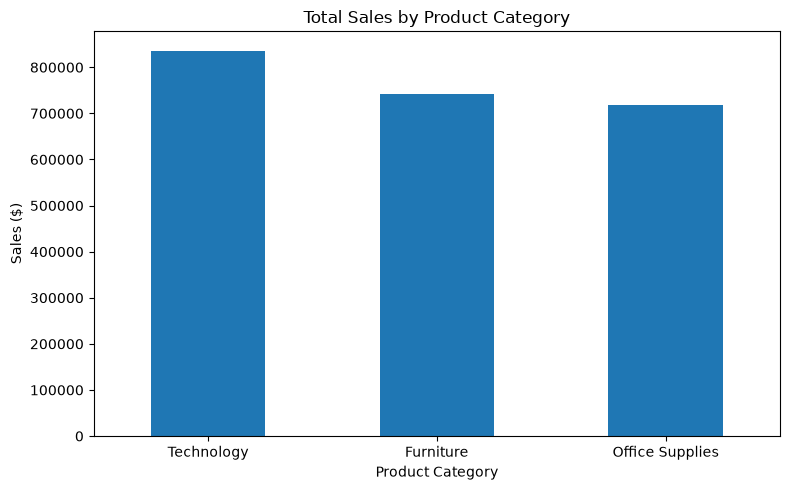

In [280]:
# Sales by Category
category_performance["Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Product Category",
    xlabel="Product Category",
    ylabel="Sales ($)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

8. Calculate Profit Margin by Category

In [281]:
# Calculate profit margin by category
category_performance["Profit Margin (%)"] = (
    category_performance["Profit"]
    / category_performance["Sales"]
) * 100

# Display category performance
category_performance.round(2)

,Sales,Profit,Profit Margin (%)
Category,,,
Technology,836154.03,145454.95,17.40
Furniture,741999.80,18451.27,2.49
Office Supplies,719047.03,122490.80,17.04


visualizing the profit margins:

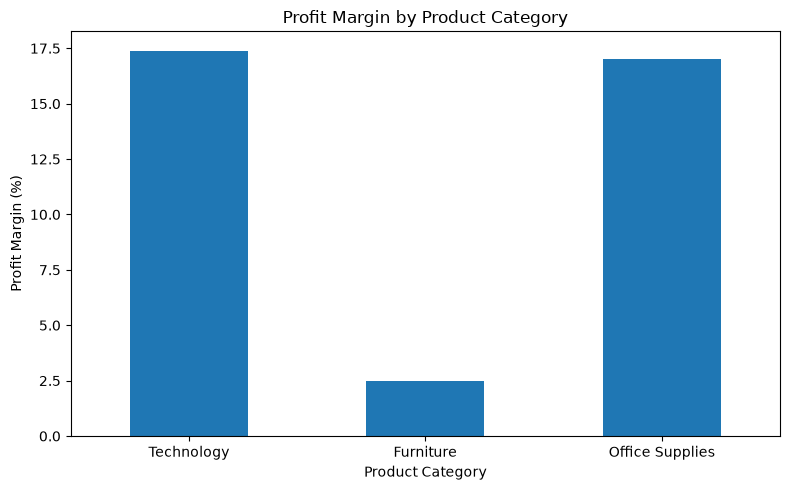

In [282]:
# Profit Margin by Category
category_performance["Profit Margin (%)"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Profit Margin by Product Category",
    xlabel="Product Category",
    ylabel="Profit Margin (%)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

9. Analyze Sales and Profit by Sub-Category

In [283]:
# Group sales and profit by sub-category
subcategory_performance = df.groupby(
    "Sub-Category"
)[["Sales", "Profit"]].sum()

# Sort by profit from highest to lowest
subcategory_performance = subcategory_performance.sort_values(
    by="Profit",
    ascending=False
)

# Display results
subcategory_performance.round(2)

,Sales,Profit
Sub-Category,,
Copiers,149528.03,55617.82
Phones,330007.05,44515.73
Accessories,167380.32,41936.64
Paper,78479.21,34053.57
Binders,203412.73,30221.76
Chairs,328449.10,26590.17
Storage,223843.61,21278.83
Appliances,107532.16,18138.01
Furnishings,91705.16,13059.14


10. Visualize Profit by Sub-Category

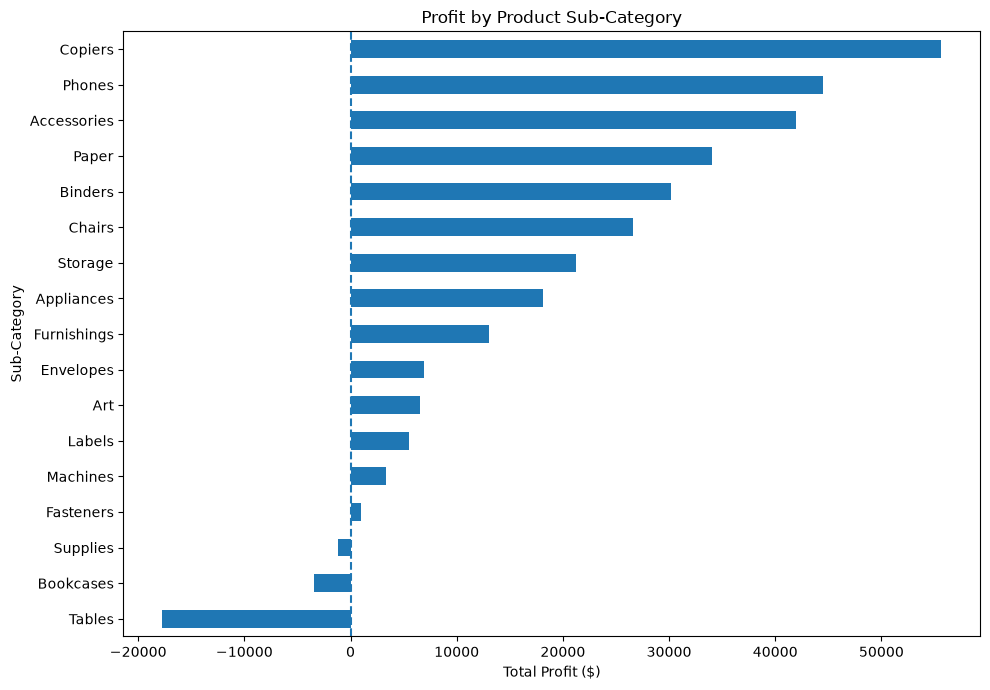

In [284]:
# Profit by Sub-Category
subcategory_performance["Profit"].sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Profit by Product Sub-Category",
    xlabel="Total Profit ($)",
    ylabel="Sub-Category"
)

plt.axvline(x=0, linestyle="--")
plt.tight_layout()
plt.show()

11. Analyze Sales Trends Over Time

11.1 Monthly Sales Analysis

In [285]:
# Group sales by month
monthly_sales = df.groupby(
    pd.Grouper(key="Order Date", freq="MS")
)["Sales"].sum()

# Display monthly sales
monthly_sales.head(12)

Order Date
2014-01-01    14236.8950
2014-02-01     4519.8920
2014-03-01    55691.0090
2014-04-01    28295.3450
2014-05-01    23648.2870
2014-06-01    34595.1276
2014-07-01    33946.3930
2014-08-01    27909.4685
2014-09-01    81777.3508
2014-10-01    31453.3930
2014-11-01    78628.7167
2014-12-01    69545.6205
Freq: MS, Name: Sales, dtype: float64

11.2 Visualize Monthly Sales

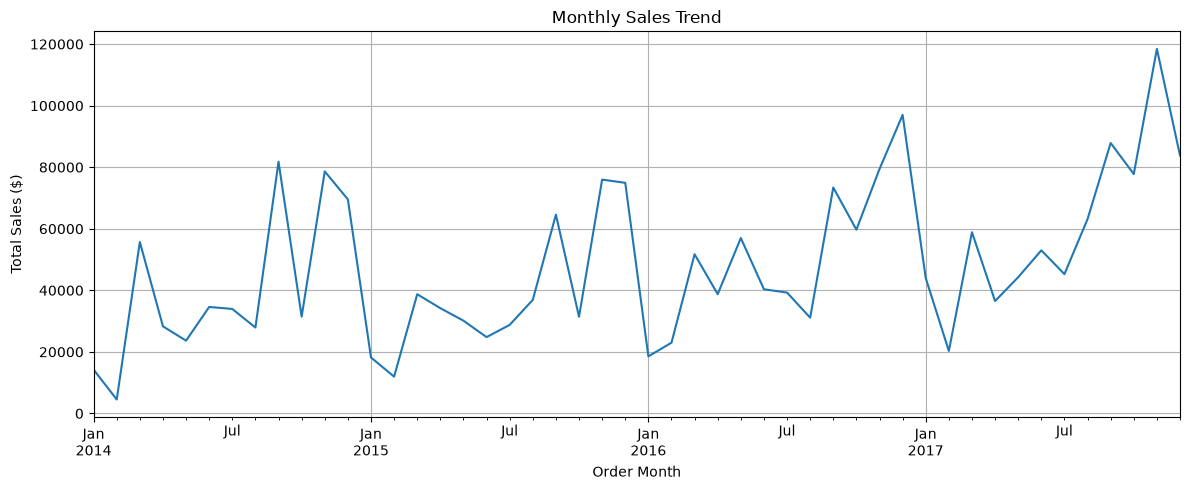

In [286]:
# Monthly Sales Trend
monthly_sales.plot(
    figsize=(12, 5),
    title="Monthly Sales Trend",
    xlabel="Order Month",
    ylabel="Total Sales ($)"
)

plt.grid(True)
plt.tight_layout()
plt.show()

12. Analyze Yearly Sales Growth

12.1 Calculate Annual Sales

In [287]:
# Calculate yearly sales
yearly_sales = df.groupby("Order Year")["Sales"].sum()

# Display annual sales
yearly_sales.round(2)

Order Year
2014    484247.50
2015    470532.51
2016    609205.60
2017    733215.26
Name: Sales, dtype: float64

12.2 Visualize Yearly Sales

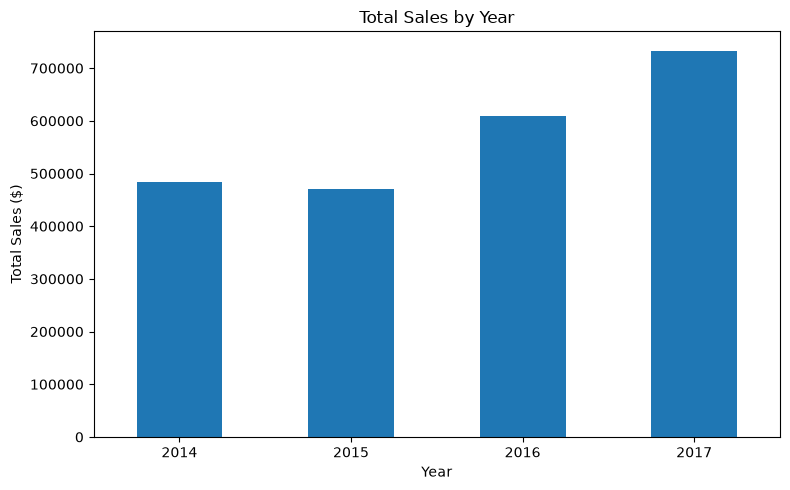

In [288]:
# Yearly Sales Comparison
yearly_sales.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Year",
    xlabel="Year",
    ylabel="Total Sales ($)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

12.3 Calculate Year-over-Year Growth

In [289]:
# Calculate yearly sales growth percentage
yearly_growth = yearly_sales.pct_change() * 100

# Display growth
yearly_growth.round(2)

Order Year
2014      NaN
2015    -2.83
2016    29.47
2017    20.36
Name: Sales, dtype: float64

13. Analyze Yearly Profit

13.1 Calculate yearly profit

In [290]:
# Calculate yearly profit
yearly_profit = df.groupby("Order Year")["Profit"].sum()

print("Yearly Profit:")
print(yearly_profit.round(2))

Yearly Profit:
Order Year
2014    49543.97
2015    61618.60
2016    81795.17
2017    93439.27
Name: Profit, dtype: float64


13.2 Visualize yearly profit

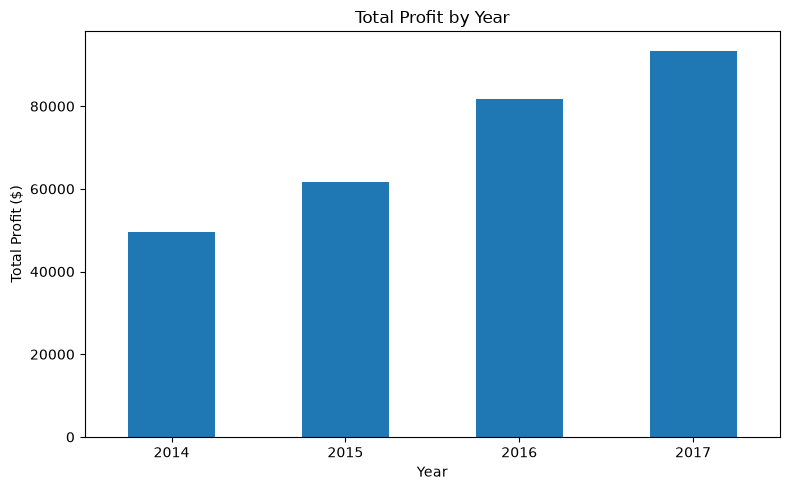

In [291]:
# Yearly Profit Comparison
yearly_profit.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Profit by Year",
    xlabel="Year",
    ylabel="Total Profit ($)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

13.3 Calculate yearly profit growth

In [292]:
# Year-over-year profit growth
profit_growth = yearly_profit.pct_change() * 100

print("Yearly Profit Growth (%):")
print(profit_growth.round(2))

Yearly Profit Growth (%):
Order Year
2014      NaN
2015    24.37
2016    32.74
2017    14.24
Name: Profit, dtype: float64


14. Compare Sales Growth and Profit Growth

In [293]:
# Combine yearly sales and profit
yearly_performance = pd.DataFrame({
    "Sales": yearly_sales,
    "Profit": yearly_profit
})

# Calculate profit margin
yearly_performance["Profit Margin (%)"] = (
    yearly_performance["Profit"]
    / yearly_performance["Sales"]
) * 100

# Calculate growth rates
yearly_performance["Sales Growth (%)"] = (
    yearly_performance["Sales"].pct_change() * 100
)

yearly_performance["Profit Growth (%)"] = (
    yearly_performance["Profit"].pct_change() * 100
)

# Display final comparison
yearly_performance.round(2)

,Sales,Profit,Profit Margin (%),Sales Growth (%),Profit Growth (%)
Order Year,,,,,
2014,484247.50,49543.97,10.23,NaN,NaN
2015,470532.51,61618.60,13.10,-2.83,24.37
2016,609205.60,81795.17,13.43,29.47,32.74
2017,733215.26,93439.27,12.74,20.36,14.24


15. Customer Analysis

15.1 Top 10 Customers by Sales

In [294]:
# Calculate sales and profit by customer
customer_performance = df.groupby(
    ["Customer ID", "Customer Name"]
)[["Sales", "Profit"]].sum()

# Sort by sales
top_customers = customer_performance.sort_values(
    by="Sales",
    ascending=False
)

# Display top 10 customers
top_customers.head(10).round(2)

,,Sales,Profit
Customer ID,Customer Name,,
SM-20320,Sean Miller,25043.05,-1980.74
TC-20980,Tamara Chand,19052.22,8981.32
RB-19360,Raymond Buch,15117.34,6976.10
TA-21385,Tom Ashbrook,14595.62,4703.79
AB-10105,Adrian Barton,14473.57,5444.81
KL-16645,Ken Lonsdale,14175.23,806.86
SC-20095,Sanjit Chand,14142.33,5757.41
HL-15040,Hunter Lopez,12873.30,5622.43
SE-20110,Sanjit Engle,12209.44,2650.68


15.2 Visualize Top 10 Customers

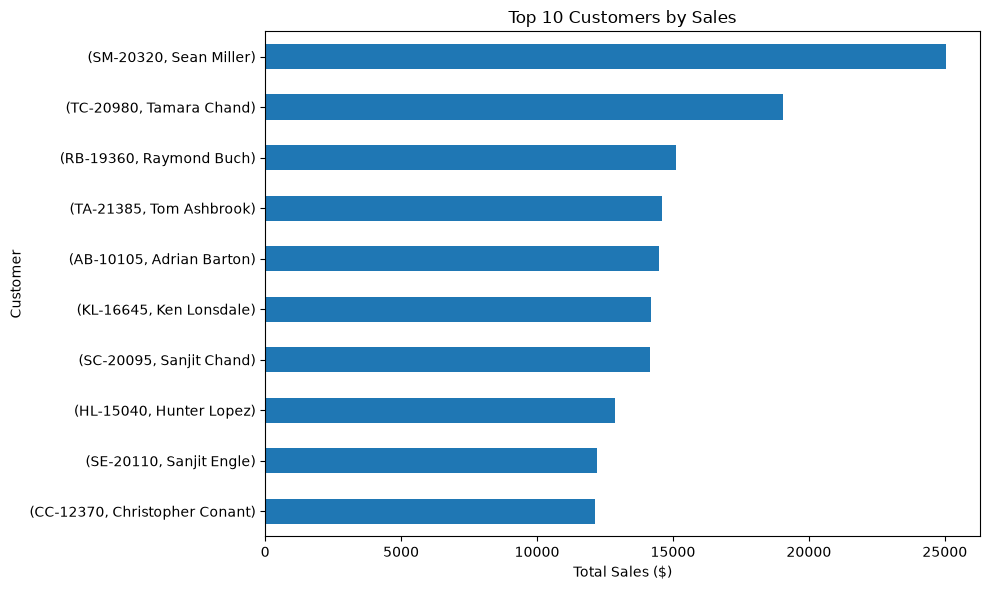

In [295]:
# Top 10 customers by sales
top_customers["Sales"].head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Customers by Sales",
    xlabel="Total Sales ($)",
    ylabel="Customer"
)

plt.tight_layout()
plt.show()

16. Identify the Most Profitable Customers

16.1 Top 10 customers by profit

In [296]:
# Sort customers by profit
top_profit_customers = customer_performance.sort_values(
    by="Profit",
    ascending=False
)

# Display top 10 most profitable customers
top_profit_customers.head(10).round(2)

,,Sales,Profit
Customer ID,Customer Name,,
TC-20980,Tamara Chand,19052.22,8981.32
RB-19360,Raymond Buch,15117.34,6976.10
SC-20095,Sanjit Chand,14142.33,5757.41
HL-15040,Hunter Lopez,12873.30,5622.43
AB-10105,Adrian Barton,14473.57,5444.81
TA-21385,Tom Ashbrook,14595.62,4703.79
CM-12385,Christopher Martinez,8954.02,3899.89
KD-16495,Keith Dawkins,8181.26,3038.63
AR-10540,Andy Reiter,6608.45,2884.62


16.2 Visualize the results

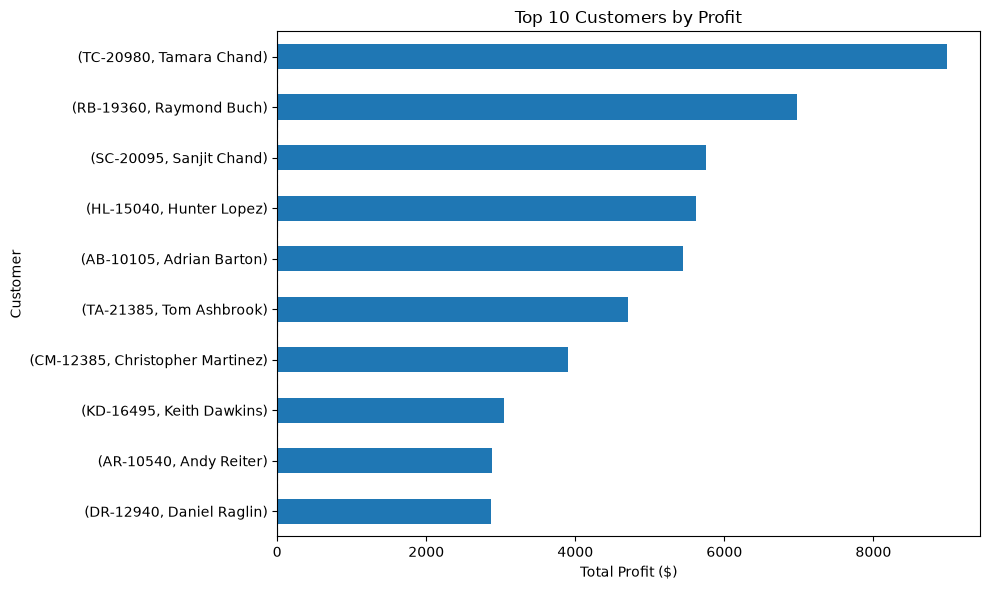

In [297]:
# Top 10 customers by profit
top_profit_customers["Profit"].head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Customers by Profit",
    xlabel="Total Profit ($)",
    ylabel="Customer"
)

plt.axvline(x=0, linestyle="--")
plt.tight_layout()
plt.show()

16.3 Compare the top sales and profit customers

In [298]:
# Compare top 10 customers by sales and profit
customer_comparison = pd.DataFrame({
    "Top by Sales": top_customers.head(10).index.get_level_values("Customer Name"),
    "Top by Profit": top_profit_customers.head(10).index.get_level_values("Customer Name")
})

customer_comparison

,Top by Sales,Top by Profit
0,Sean Miller,Tamara Chand
1,Tamara Chand,Raymond Buch
2,Raymond Buch,Sanjit Chand
3,Tom Ashbrook,Hunter Lopez
4,Adrian Barton,Adrian Barton
5,Ken Lonsdale,Tom Ashbrook
6,Sanjit Chand,Christopher Martinez
7,Hunter Lopez,Keith Dawkins
8,Sanjit Engle,Andy Reiter
9,Christopher Conant,Daniel Raglin


17. Customer Segmentation by Customer Segment

17.1 Group performance

In [299]:
# Customer segment analysis
segment_performance = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Customers=("Customer ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
)

# Calculate profit margin
segment_performance["Profit_Margin (%)"] = (
    segment_performance["Total_Profit"]
    / segment_performance["Total_Sales"]
) * 100

segment_performance.round(2)

,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Total_Quantity,Profit_Margin (%)
Segment,,,,,,
Consumer,1161401.34,134119.21,2586,409,19521,11.55
Corporate,706146.37,91979.13,1514,236,11608,13.03
Home Office,429653.15,60298.68,909,148,6744,14.03


17.2 Visualize sales by segment

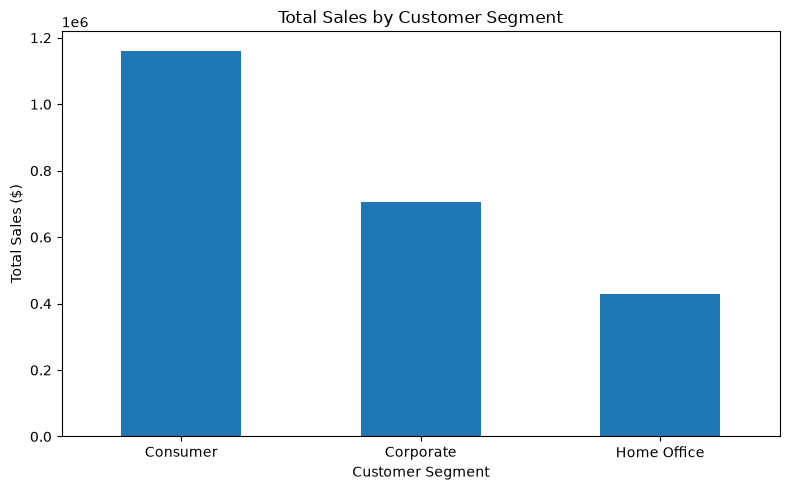

In [300]:
segment_performance["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Customer Segment",
    xlabel="Customer Segment",
    ylabel="Total Sales ($)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

17.3 Visualize profit by segment

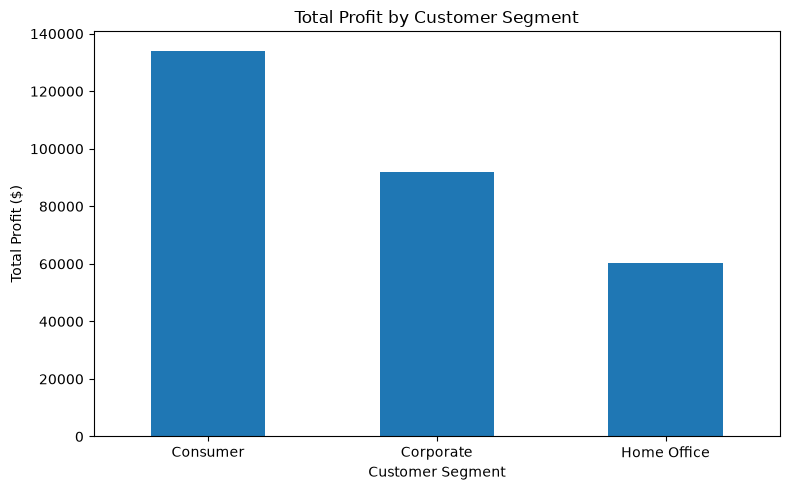

In [301]:
segment_performance["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Profit by Customer Segment",
    xlabel="Customer Segment",
    ylabel="Total Profit ($)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

18. Regional Sales and Profit Analysis

18.1 Calculate regional performance

In [302]:
# Regional sales and profit analysis
regional_performance = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Customers=("Customer ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
)

# Calculate regional profit margin
regional_performance["Profit_Margin (%)"] = (
    regional_performance["Total_Profit"]
    / regional_performance["Total_Sales"]
) * 100

# Sort regions by sales
regional_performance = regional_performance.sort_values(
    by="Total_Sales",
    ascending=False
)

regional_performance.round(2)

,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Total_Quantity,Profit_Margin (%)
Region,,,,,,
West,725457.82,108418.45,1611,686,12266,14.94
East,678781.24,91522.78,1401,674,10618,13.48
Central,501239.89,39706.36,1175,629,8780,7.92
South,391721.90,46749.43,822,512,6209,11.93


18.2 Visualize regional sales

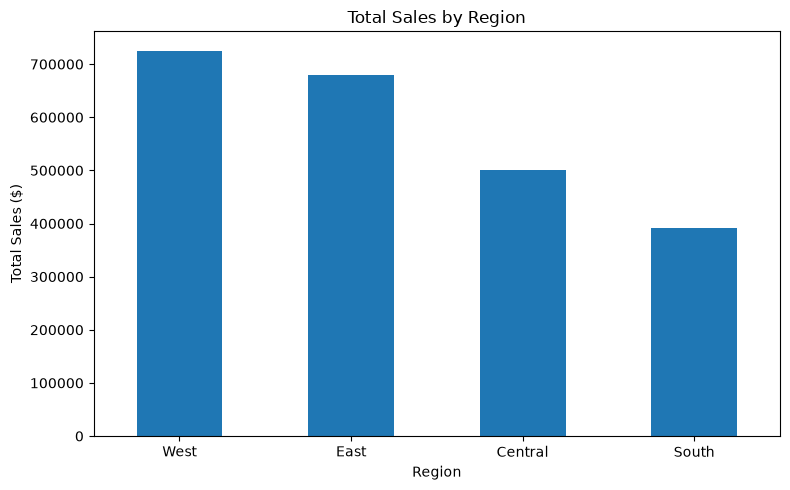

In [303]:
regional_performance["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Region",
    xlabel="Region",
    ylabel="Total Sales ($)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

18.3 Visualize regional profit

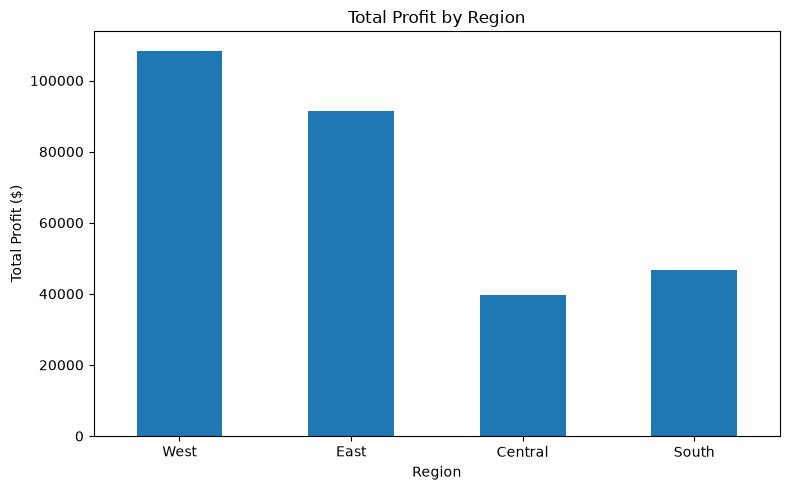

In [304]:
regional_performance["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Profit by Region",
    xlabel="Region",
    ylabel="Total Profit ($)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

19. Investigate Regional Performance by Category

19.1 Regional and category analysis

In [305]:
# Sales and profit by region and category
region_category = df.pivot_table(
    index="Region",
    columns="Category",
    values=["Sales", "Profit"],
    aggfunc="sum"
)

region_category.round(2)

Profit                                 Sales                  \
Category Furniture Office Supplies Technology  Furniture Office Supplies   
Region                                                                     
Central   -2871.05         8879.98   33697.43  163797.16       167026.42   
East       3046.17        41014.58   47462.04  208291.20       205516.06   
South      6771.21        19986.39   19991.83  117298.68       125651.31   
West      11504.95        52609.85   44303.65  252612.74       220853.25   

                     
Category Technology  
Region               
Central   170416.31  
East      264973.98  
South     148771.91  
West      251991.83

19.2 Analyze profit by region and category

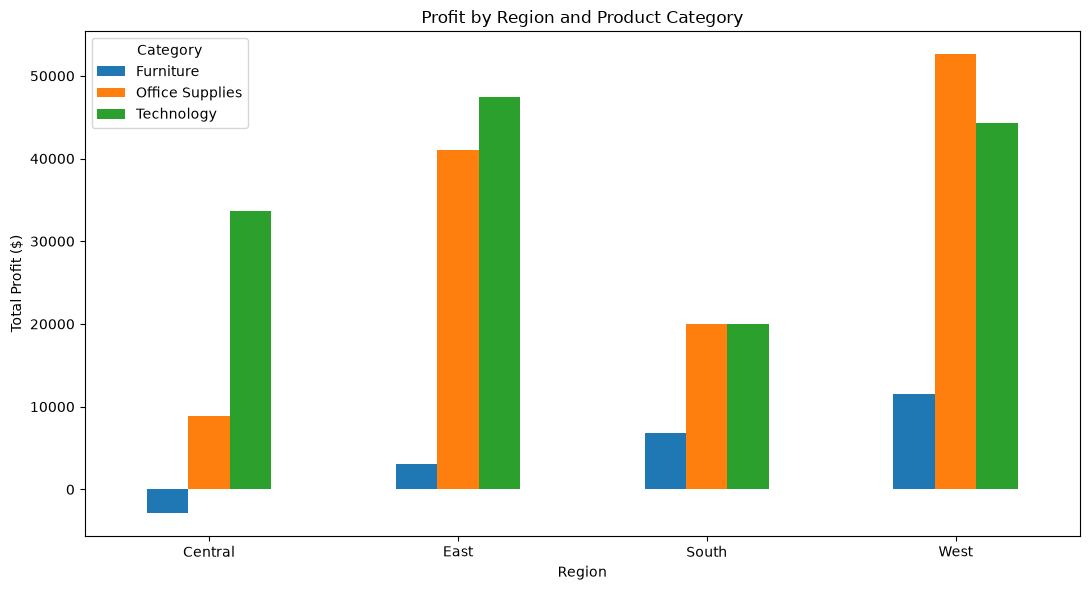

In [306]:
# Extract profit values
region_category_profit = df.pivot_table(
    index="Region",
    columns="Category",
    values="Profit",
    aggfunc="sum"
)

region_category_profit.plot(
    kind="bar",
    figsize=(11, 6),
    title="Profit by Region and Product Category",
    xlabel="Region",
    ylabel="Total Profit ($)"
)

plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

### Regional and Category Profitability — Key Insights

The analysis shows that Technology and Office Supplies are the main
contributors to overall business profitability.

Technology generates the highest profit, followed by Office Supplies.
Furniture has the weakest performance and records a loss in the Central
region.

The Central region has the lowest overall profit and profit margin.
Its negative Furniture profit and comparatively low Office Supplies
profit contribute to this result.

The West region performs strongly across all three product categories,
while the East region generates particularly strong profits from
Technology and Office Supplies.

Further investigation is required to identify whether discounts,
product mix, or individual products are responsible for Furniture's
poor performance.

20. Investigate discount impact

In [307]:
# Analyse average discount and profit by category

discount_analysis = df.groupby("Category").agg(
    Average_Discount=("Discount", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

discount_analysis["Profit_Margin (%)"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"]
) * 100

discount_analysis.round(3)

,Average_Discount,Total_Sales,Total_Profit,Profit_Margin (%)
Category,,,,
Furniture,0.174,741999.795,18451.273,2.487
Office Supplies,0.157,719047.032,122490.801,17.035
Technology,0.132,836154.033,145454.948,17.396


### Discount and Category Profitability Analysis

Furniture has the highest average discount of 17.4%, but its
profit margin is only 2.49%.

Office Supplies has an average discount of 15.7% and a profit
margin of 17.04%, while Technology has the lowest average
discount of 13.2% and the highest profit margin of 17.40%.

These findings suggest a possible association between discount
levels and profitability. However, further analysis is required
to determine whether discounts directly affect profit.

Furniture should be investigated further, particularly its
discount strategy, product sub-categories, and loss-making orders.

21. Does a higher discount mean a greater loss?

In [308]:
# Analyse profit by discount level

discount_performance = df.groupby("Discount").agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean")
)

discount_performance.round(2)

,Total_Orders,Total_Sales,Total_Profit,Average_Profit
Discount,,,,
0.00,2644,1087908.47,320987.60,66.90
0.10,89,54369.35,9029.18,96.06
0.15,51,27558.52,1418.99,27.29
0.20,2407,764594.37,90337.31,24.70
0.30,211,103226.66,-10369.28,-45.68
0.32,27,14493.46,-2391.14,-88.56
0.40,185,116417.78,-23057.05,-111.93
0.45,10,5484.97,-2493.11,-226.65
0.50,64,58918.54,-20506.43,-310.70


### Discount-Level Profitability Analysis

The analysis reveals a strong association between discount levels
and profitability.

Transactions with discounts of 0%, 10%, 15%, and 20% generate
positive total profits. However, all discount levels from 30%
onwards in this dataset generate negative total profits.

The 70% discount level records the largest total loss of
approximately $40,075, while the 50% discount level has the
lowest average profit of approximately -$310.70.

These findings indicate that aggressive discounting may create
significant profitability risks.

However, this analysis is descriptive and does not establish
causation. Further investigation should consider product
categories, sub-categories, quantities, and order characteristics.

22. Visualise discount versus profit

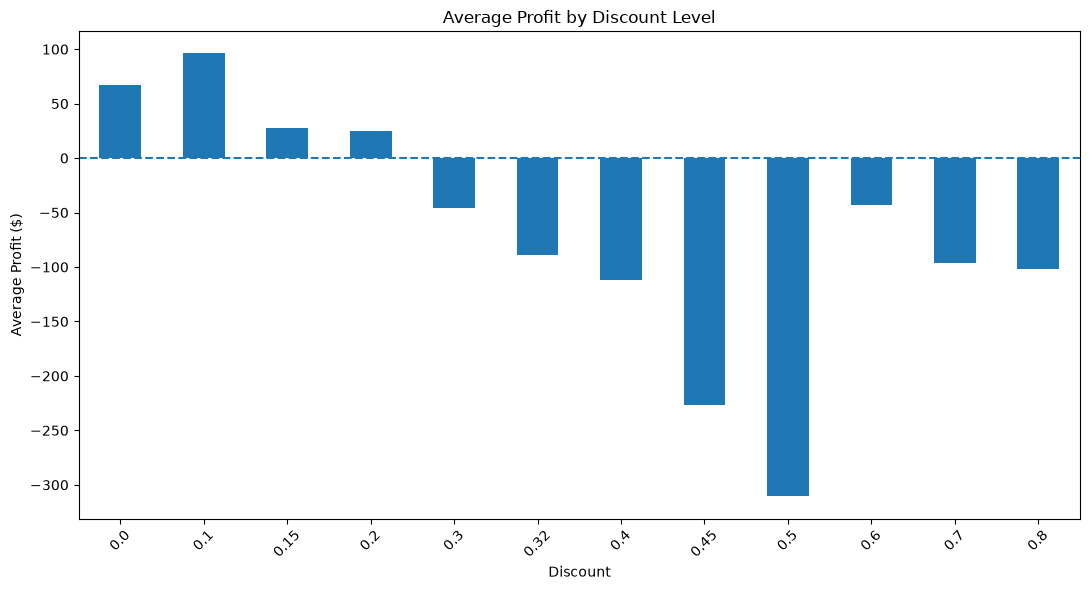

In [309]:
# Average profit by discount level

discount_performance["Average_Profit"].plot(
    kind="bar",
    figsize=(11, 6),
    title="Average Profit by Discount Level",
    xlabel="Discount",
    ylabel="Average Profit ($)"
)

plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Average Profit by Discount Level

The analysis shows that average profitability varies considerably
across discount levels.

The 10% discount level records the highest average profit,
approximately $96 per order line. Transactions with discounts
of 15% and 20% remain profitable, but their average profits
are considerably lower.

At discount levels of 30% and above, average profit becomes
negative. The 50% discount level records the largest average
loss, approximately $311 per order line.

The relationship is not perfectly linear, as the average loss
at 60% is smaller than at 45% and 50%. This variation may be
associated with differences in product mix and transaction
characteristics.

Overall, the findings suggest that aggressive discounting
is associated with reduced profitability. Further analysis
is required to investigate the impact across product categories.

23. Discount impact by category

In [310]:
# Average profit by discount and product category

category_discount = df.pivot_table(
    index="Discount",
    columns="Category",
    values="Profit",
    aggfunc="mean"
)

category_discount.round(2)

Category,Furniture,Office Supplies,Technology
Discount,,,
0.00,69.54,41.71,158.88
0.10,93.57,67.88,416.04
0.15,27.29,NaN,NaN
0.20,10.19,17.28,54.74
0.30,-48.18,NaN,65.21
0.32,-88.56,NaN,NaN
0.40,-215.83,NaN,-52.44
0.45,-226.65,NaN,NaN
0.50,-238.36,NaN,-636.27


### Discount Impact Across Product Categories

The category-level analysis reveals different profitability
patterns across Furniture, Office Supplies, and Technology.

Furniture experiences negative average profit from the
30% discount level onwards in the observed groups.

Office Supplies remains profitable at discount levels up
to 20%, while the observed 70% and 80% discount groups
record negative average profits.

Technology maintains positive average profit at 30% discount,
but records substantial losses at 40%, 50%, and 70%.

These findings suggest that discount sensitivity varies
between product categories. Furniture appears particularly
vulnerable to aggressive discounting.

However, the number of observations varies across discount
levels, and some category-discount combinations have no
records. Therefore, these findings should be interpreted
with consideration of sample size and product mix.

24. Check sample sizes

In [311]:
# Count order lines by discount and category

discount_sample_size = df.pivot_table(
    index="Discount",
    columns="Category",
    values="Profit",
    aggfunc="count",
    fill_value=0
)

discount_sample_size

Category,Furniture,Office Supplies,Technology
Discount,,,
0.00,836,3129,833
0.10,76,16,2
0.15,52,0,0
0.20,615,2201,841
0.30,222,0,5
0.32,27,0,0
0.40,75,0,131
0.45,11,0,0
0.50,54,0,12


### Sample Size Validation for Discount Analysis

Sample sizes were examined to assess the reliability of
category-level discount comparisons.

Furniture has substantial observations at 20% and 30%
discount levels, with 615 and 222 order lines respectively.
Both the average profit and sample size indicate that the
decline in profitability deserves further investigation.

Technology records substantial average losses at 50% and
70% discounts. However, these groups contain only 12 and
23 observations, so the results should be interpreted cautiously.

Office Supplies has 380 observations at 70% discount and
300 observations at 80% discount. Both groups record
negative average profits.

The analysis demonstrates the importance of considering
sample sizes when interpreting grouped averages. Missing
category-discount combinations represent unavailable
observations rather than zero profitability.

26. Visualise the results with a heatmap

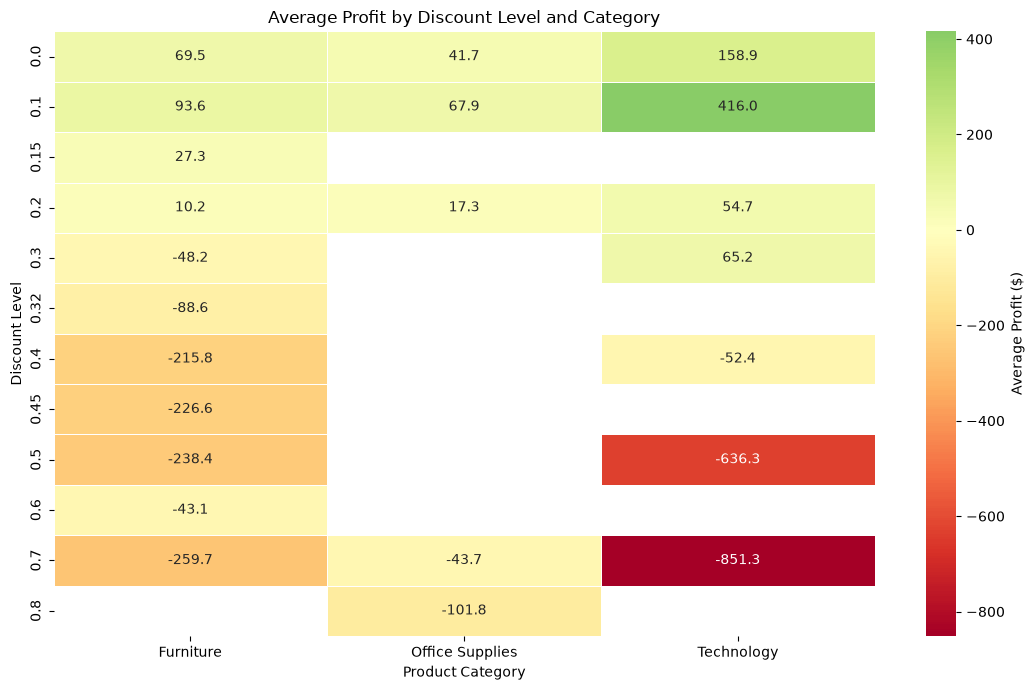

In [312]:
# Heatmap: Average profit by discount and category

plt.figure(figsize=(11, 7))

sns.heatmap(
    category_discount,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Average Profit ($)"}
)

plt.title("Average Profit by Discount Level and Category")
plt.xlabel("Product Category")
plt.ylabel("Discount Level")

plt.tight_layout()
plt.show()

### Heatmap Analysis: Discount and Category Profitability

The heatmap demonstrates that the relationship between
discount levels and profitability varies across product categories.

Furniture records negative average profit from the 30% discount
level onwards in the observed groups. This indicates a potential
risk associated with aggressive discounting in this category.

Office Supplies remains profitable at discount levels up to 20%,
while its observed 70% and 80% discount groups generate losses.

Technology demonstrates the greatest variation. Its average
profit reaches $416.04 at a 10% discount but falls to -$851.27
at a 70% discount.

The findings suggest that discount strategies should be
evaluated separately for each product category rather than
using a single discount policy across the business.

However, the results are descriptive. Different sample sizes,
product characteristics, and transaction values may influence
the observed profitability patterns.

27. Identify the products responsible for losses

In [313]:
# Identify the 10 most loss-making products

product_loss = df.groupby(
    ["Product ID", "Product Name", "Category", "Sub-Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Average_Discount=("Discount", "mean")
)

product_loss = product_loss.sort_values(
    by="Total_Profit",
    ascending=True
)

product_loss.head(10).round(2)

,,,,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Average_Discount
Product ID,Product Name,Category,Sub-Category,,,,,
TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,11099.96,-8879.97,9,3,0.53
TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,16829.90,-4589.97,18,4,0.40
TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.98,-3839.99,4,1,0.50
FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,Furniture,Tables,9917.64,-2876.12,27,5,0.28
FUR-TA-10001889,Bush Advantage Collection Racetrack Conference Table,Furniture,Tables,9544.72,-1934.40,33,7,0.35
OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.07,-1878.17,27,6,0.45
TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferencing Unit,Technology,Machines,22638.48,-1811.08,6,1,0.50
OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Opener,Office Supplies,Supplies,16656.20,-1299.18,22,6,0.10
FUR-TA-10001950,Balt Solid Wood Round Tables,Furniture,Tables,6518.75,-1201.06,19,4,0.20



Total_Sales	Total_Profit	Total_Quantity	Total_Orders	Average_Discount
Product ID	Product Name	Category	Sub-Category					
TEC-MA-10000418	Cubify CubeX 3D Printer Double Head Print	Technology	Machines	11099.96	-8879.97	9	3	0.53
TEC-MA-10000822	Lexmark MX611dhe Monochrome Laser Printer	Technology	Machines	16829.90	-4589.97	18	4	0.40
TEC-MA-10004125	Cubify CubeX 3D Printer Triple Head Print	Technology	Machines	7999.98	-3839.99	4	1	0.50
FUR-TA-10000198	Chromcraft Bull-Nose Wood Oval Conference Tables & Bases	Furniture	Tables	9917.64	-2876.12	27	5	0.28
FUR-TA-10001889	Bush Advantage Collection Racetrack Conference Table	Furniture	Tables	9544.72	-1934.40	33	7	0.35
OFF-BI-10004995	GBC DocuBind P400 Electric Binding System	Office Supplies	Binders	17965.07	-1878.17	27	6	0.45
TEC-MA-10002412	Cisco TelePresence System EX90 Videoconferencing Unit	Technology	Machines	22638.48	-1811.08	6	1	0.50
OFF-SU-10002881	Martin Yale Chadless Opener Electric Letter Opener	Office Supplies	Supplies	16656.20	-1299.18	22	6	0.10
FUR-TA-10001950	Balt Solid Wood Round Tables	Furniture	Tables	6518.75	-1201.06	19	4	0.20
FUR-TA-10004289	BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables	Furniture	Tables	1706.25	-1148.44	15	3	0.48


28. Are these products consistently unprofitable?

In [314]:
# Investigate order-level performance of the five worst products

worst_products = product_loss.head(5).index.get_level_values(
    "Product ID"
)

worst_product_details = df[
    df["Product ID"].isin(worst_products)
][[
    "Order ID",
    "Order Date",
    "Product ID",
    "Product Name",
    "Category",
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]].sort_values(
    by="Profit",
    ascending=True
)

worst_product_details.round(2)

C:\Users\dharm\AppData\Local\Temp\ipykernel_13052\3774020911.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  worst_product_details.round(2)


,Order ID,Order Date,Product ID,Product Name,Category,Sales,Quantity,Discount,Profit
7772,CA-2016-108196,2016-11-25,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,4499.98,5,0.70,-6599.98
683,US-2017-168116,2017-11-04,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,7999.98,4,0.50,-3839.99
3011,CA-2017-134845,2017-04-17,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,2549.98,5,0.70,-3399.98
3151,CA-2015-147830,2015-12-15,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,1799.99,2,0.70,-2639.99
9639,CA-2015-116638,2015-01-28,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,4297.64,13,0.40,-1862.31
165,CA-2014-139892,2014-09-08,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,8159.95,8,0.40,-1359.99
5320,US-2017-162558,2017-10-02,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,2314.12,7,0.40,-1002.78
463,CA-2016-109869,2016-04-22,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,1272.63,6,0.50,-814.48
5066,CA-2017-142090,2017-11-30,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,1781.68,7,0.40,-653.28
262,US-2014-106992,2014-09-19,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,3059.98,3,0.40,-510.00


### Transaction-Level Investigation of Loss-Making Products

The transaction-level analysis reveals that several products
experience substantial variations in profitability across
individual transactions.

The Cubify CubeX 3D Printer Double Head generated losses of
$6,599.98 and $2,639.99 at a 70% discount, while another
transaction involving the same product generated a profit
of $360 at a 20% discount.

Similarly, the Lexmark MX611dhe Printer recorded significant
losses at discounts of 40% and 70%, but generated a profit
of $680 at a 10% discount.

Furniture conference tables also demonstrate differences
in profitability across transactions.

These findings indicate that individual product profitability
depends on transaction characteristics, including discount
levels and quantities.

The analysis suggests that businesses should monitor
profitability at both product and transaction levels rather
than relying exclusively on aggregated product performance.

However, the observed relationships do not establish
that discounts alone cause the losses.

29. Quantify the financial impact of discounting

In [315]:
# Analyse the percentage of profitable and loss-making order lines

discount_risk = df.groupby("Discount").agg(
    Total_Transactions=("Profit", "count"),
    Profitable_Lines=("Profit", lambda x: (x > 0).sum()),
    Loss_Making_Lines=("Profit", lambda x: (x < 0).sum()),
    Total_Profit=("Profit", "sum")
)

discount_risk["Loss_Making (%)"] = (
    discount_risk["Loss_Making_Lines"] /
    discount_risk["Total_Transactions"]
) * 100

discount_risk["Profitable (%)"] = (
    discount_risk["Profitable_Lines"] /
    discount_risk["Total_Transactions"]
) * 100

discount_risk.round(2)

,Total_Transactions,Profitable_Lines,Loss_Making_Lines,Total_Profit,Loss_Making (%),Profitable (%)
Discount,,,,,,
0.00,4798,4768,0,320987.60,0.00,99.37
0.10,94,90,4,9029.18,4.26,95.74
0.15,52,35,17,1418.99,32.69,67.31
0.20,3657,3133,502,90337.31,13.73,85.67
0.30,227,6,208,-10369.28,91.63,2.64
0.32,27,0,27,-2391.14,100.00,0.00
0.40,206,26,180,-23057.05,87.38,12.62
0.45,11,0,11,-2493.11,100.00,0.00
0.50,66,0,66,-20506.43,100.00,0.00


### Transaction-Level Profitability Risk by Discount

The analysis examines the proportion of individual order lines
that generate positive or negative profit at different
discount levels.

At a 0% discount, 99.37% of transactions are profitable.
The 10% discount group also performs strongly, with 95.74%
profitable transactions.

At a 30% discount, 91.63% of transactions generate losses.
The 32%, 45%, 50%, 60%, 70%, and 80% discount groups record
100% loss-making transactions in the observed dataset.

The 70% discount group produces the largest total loss,
approximately $40,075.36, across 418 transactions.

These findings indicate a strong association between
aggressive discounting and transaction-level profitability risk.

However, the results are descriptive and do not establish
causation. Product mix, transaction quantities, and costs
may also influence profitability.

30. Visualise transaction-level risk

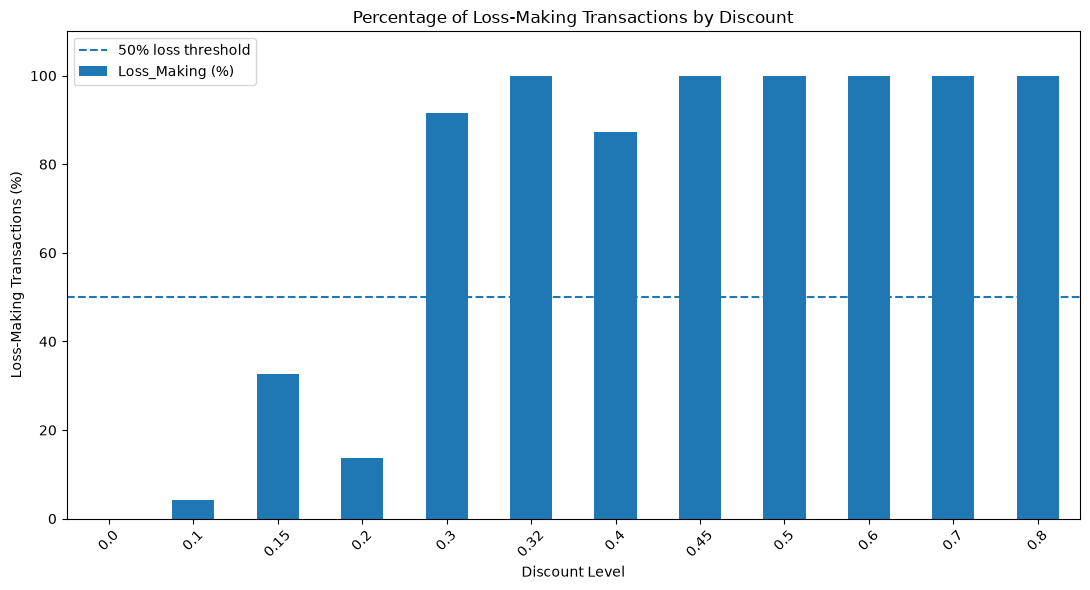

In [316]:
# Percentage of loss-making transactions by discount

discount_risk["Loss_Making (%)"].plot(
    kind="bar",
    figsize=(11, 6),
    title="Percentage of Loss-Making Transactions by Discount",
    xlabel="Discount Level",
    ylabel="Loss-Making Transactions (%)",
    ylim=(0, 110)
)

plt.axhline(
    y=50,
    linestyle="--",
    label="50% loss threshold"
)

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation: Loss-Making Order Lines by Discount Level

The analysis reveals a substantial association between discount levels
and order-line profitability.

At discount levels of 0% and 10%, the proportion of loss-making
order lines is very low. However, at a 30% discount, the loss-making
rate increases sharply to approximately 92%.

All observed order lines at discount levels of 32%, 45%, 50%, 60%,
70%, and 80% recorded negative profits. The 40% discount group
also showed a high loss-making rate of approximately 87%.

The relationship is not perfectly linear, as demonstrated by the
decrease in the loss-making rate from 15% to 20%.

These findings suggest that high discount levels are associated
with increased profitability risk. However, this is an observational
analysis and does not establish a causal relationship.

31. Identify what predicts a loss

In [317]:
# Create a binary target variable
# 1 = Loss-making order line
# 0 = Non-loss-making order line

df["Loss_Making"] = (df["Profit"] < 0).astype(int)

# Check the target distribution
df["Loss_Making"].value_counts()

Loss_Making
0    8123
1    1871
Name: count, dtype: int64

32. prepare features

In [318]:
# Select features for loss prediction

features = [
    "Discount",
    "Quantity",
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode"
]

X = df[features]
y = df["Loss_Making"]

# Check feature data
print("Feature shape:", X.shape)
print("\nTarget shape:", y.shape)

X.head()

Feature shape: (9994, 7)

Target shape: (9994,)


,Discount,Quantity,Category,Sub-Category,Region,Segment,Ship Mode
0,0.00,2,Furniture,Bookcases,South,Consumer,Second Class
1,0.00,3,Furniture,Chairs,South,Consumer,Second Class
2,0.00,2,Office Supplies,Labels,West,Corporate,Second Class
3,0.45,5,Furniture,Tables,South,Consumer,Standard Class
4,0.20,2,Office Supplies,Storage,South,Consumer,Standard Class


33. Encode categorical features and split the dataset

In [319]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Separate numerical and categorical features
numeric_features = ["Discount", "Quantity"]

categorical_features = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (7995, 7)
Testing features: (1999, 7)

Training target distribution:
Loss_Making
0    0.813
1    0.187
Name: proportion, dtype: float64

Testing target distribution:
Loss_Making
0    0.813
1    0.187
Name: proportion, dtype: float64


34. Build our first Random Forest model

In [320]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


35. Evaluate model performance

In [321]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict on unseen testing data
y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
print("MODEL PERFORMANCE")
print("=" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-loss-making", "Loss-making"],
    zero_division=0
))

MODEL PERFORMANCE
Accuracy: 0.92
Precision: 0.7238
Recall: 0.9251
F1-score: 0.8122

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Non-loss-making       0.98      0.92      0.95      1625
    Loss-making       0.72      0.93      0.81       374

       accuracy                           0.92      1999
      macro avg       0.85      0.92      0.88      1999
   weighted avg       0.93      0.92      0.92      1999



36. Confusion matrix

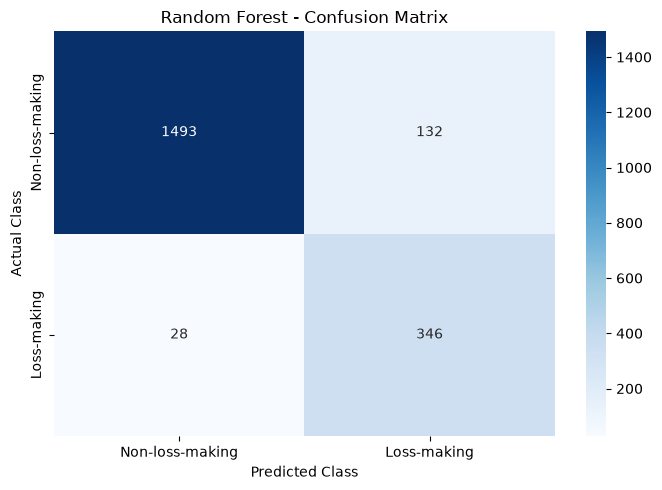

In [322]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-loss-making", "Loss-making"],
    yticklabels=["Non-loss-making", "Loss-making"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

37. Understand which features influence predictions

In [323]:
# Extract feature importance from the trained Random Forest

import pandas as pd

# Get transformed feature names
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

# Get importance scores
importance_values = rf_model.named_steps["classifier"].feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
feature_importance.head(15)

,Feature,Importance
0,num__Discount,0.616670
17,cat__Sub-Category_Paper,0.053250
8,cat__Sub-Category_Binders,0.045101
22,cat__Region_Central,0.028669
19,cat__Sub-Category_Storage,0.027501
7,cat__Sub-Category_Art,0.026327
2,cat__Category_Furniture,0.026062
25,cat__Region_West,0.021811
21,cat__Sub-Category_Tables,0.017825
3,cat__Category_Office Supplies,0.015898


38. Create a feature-importance chart

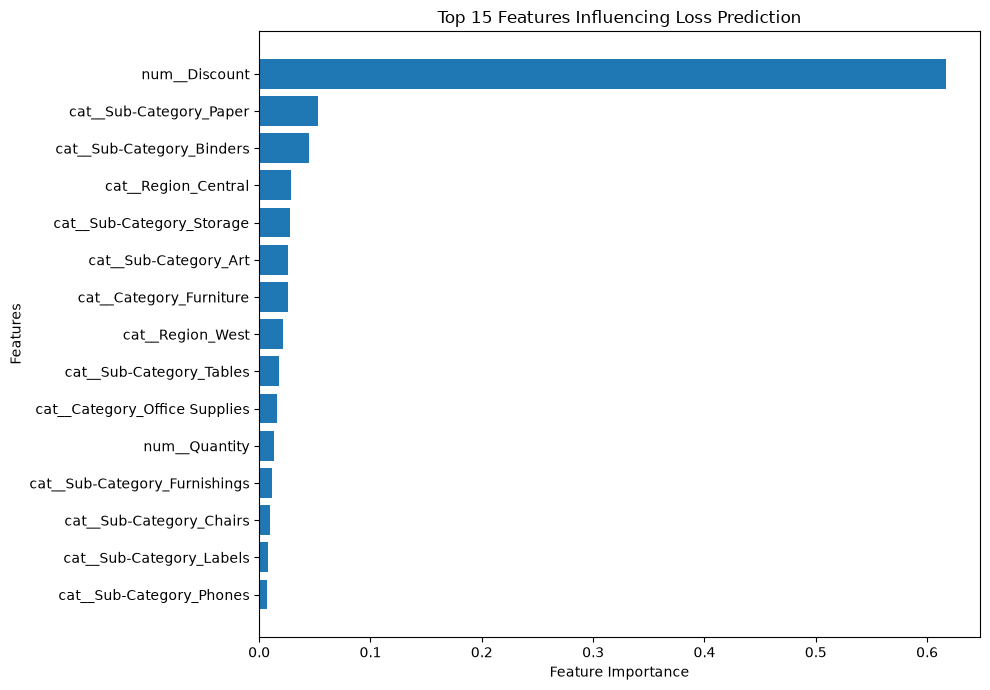

In [324]:
# Feature Importance Visualization

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features Influencing Loss Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

39. Compare the model with and without Discount

In [325]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Features without Discount
numeric_features_no_discount = ["Quantity"]

categorical_features = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode"
]

# Create a separate preprocessor
preprocessor_no_discount = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"),
         numeric_features_no_discount),

        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Create model
rf_no_discount = Pipeline(steps=[
    ("preprocessor", preprocessor_no_discount),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Same random split as the original model, but without the Discount column
X_train_no_discount = X_train.drop(columns=["Discount"])
X_test_no_discount = X_test.drop(columns=["Discount"])

# Train model
rf_no_discount.fit(X_train_no_discount, y_train)

# Predict
y_pred_no_discount = rf_no_discount.predict(X_test_no_discount)

print("Model without Discount trained successfully!")

Model without Discount trained successfully!


In [326]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],

    "With Discount": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],

    "Without Discount": [
        accuracy_score(y_test, y_pred_no_discount),
        precision_score(y_test, y_pred_no_discount),
        recall_score(y_test, y_pred_no_discount),
        f1_score(y_test, y_pred_no_discount)
    ]
})

comparison["Difference"] = (
    comparison["Without Discount"] -
    comparison["With Discount"]
)

comparison.round(4)

,Metric,With Discount,Without Discount,Difference
0,Accuracy,0.9200,0.7804,-0.1396
1,Precision,0.7238,0.4516,-0.2723
2,Recall,0.9251,0.8102,-0.1150
3,F1-score,0.8122,0.5799,-0.2323


### Comparative Experiment: Impact of Discount on Model Performance

A comparative experiment was conducted using two Random Forest
classifiers with identical hyperparameters and training/testing
observations.

The first model included all seven input features, while the second
excluded the Discount variable.

The model containing Discount achieved 92.00% accuracy, 72.38%
precision, 92.51% recall and an F1-score of 0.8122.

After removing Discount, accuracy decreased to 78.04%, precision
to 45.16%, recall to 81.02%, and F1-score to 0.5799.

These findings indicate that Discount provides substantial predictive
information for identifying loss-making order lines. Nevertheless,
the remaining variables retain some predictive capability.

The experiment demonstrates predictive dependence on Discount,
but does not establish a causal relationship between discount levels
and profitability.

40. Investigate whether the model is over-relying on Discount

In [327]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on unseen test data
perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create importance table
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

permutation_df

,Feature,Importance,Std
0,Discount,0.549280,0.014629
3,Sub-Category,0.049641,0.011419
6,Ship Mode,0.005201,0.003410
4,Region,0.001572,0.002723
5,Segment,0.000671,0.002549
1,Quantity,-0.003018,0.003325
2,Category,-0.014180,0.010493


### Permutation Feature Importance Analysis

Permutation importance was calculated using the held-out test dataset
and F1-score as the evaluation metric.

Discount demonstrated the highest importance, with a mean decrease
in F1-score of 0.5493 after random permutation. Sub-Category was the
second most important feature, with a decrease of 0.0496.

Other features, including Ship Mode, Region and Segment, showed
relatively small contributions. Quantity and Category produced
slightly negative permutation importance values.

These results support the earlier feature-removal experiment,
indicating that the predictive performance of the Random Forest
model depends heavily on discount information.

However, permutation importance measures predictive reliance rather
than causal influence. Correlated and interacting features may
affect these estimates.

41. Split data by year

In [328]:
# Ensure Order Date is in datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Create chronological training and testing datasets
train_time = df[df["Order Date"].dt.year < 2017].copy()

test_time = df[df["Order Date"].dt.year == 2017].copy()

# Select the same features used in our original model
X_train_time = train_time[features]
y_train_time = train_time["Loss_Making"]

X_test_time = test_time[features]
y_test_time = test_time["Loss_Making"]

# Display dataset sizes
print("TIME-BASED VALIDATION")
print("=" * 40)

print("Training period: 2014–2016")
print("Training rows:", len(X_train_time))

print("\nTesting period: 2017")
print("Testing rows:", len(X_test_time))

print("\nTraining loss distribution:")
print(y_train_time.value_counts(normalize=True).round(3))

print("\nTesting loss distribution:")
print(y_test_time.value_counts(normalize=True).round(3))

TIME-BASED VALIDATION
Training period: 2014–2016
Training rows: 6682

Testing period: 2017
Testing rows: 3312

Training loss distribution:
Loss_Making
0    0.813
1    0.187
Name: proportion, dtype: float64

Testing loss distribution:
Loss_Making
0    0.813
1    0.187
Name: proportion, dtype: float64


In [329]:
print("Features:")
print(features)

print("\nX columns:")
print(X.columns.tolist())

print("\nX shape:")
print(X.shape)

print("\nMissing feature columns:")
print(set(features) - set(X.columns))

Features:
['Discount', 'Quantity', 'Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']

X columns:
['Discount', 'Quantity', 'Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']

X shape:
(9994, 7)

Missing feature columns:
set()


In [330]:
print("X_train_time shape:", X_train_time.shape)
print("X_test_time shape:", X_test_time.shape)

print("\nTraining columns:")
print(X_train_time.columns.tolist())

print("\nTesting columns:")
print(X_test_time.columns.tolist())

print("\nMissing columns in training:")
print(set(features) - set(X_train_time.columns))

print("\nMissing columns in testing:")
print(set(features) - set(X_test_time.columns))

X_train_time shape: (6682, 7)
X_test_time shape: (3312, 7)

Training columns:
['Discount', 'Quantity', 'Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']

Testing columns:
['Discount', 'Quantity', 'Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']

Missing columns in training:
set()

Missing columns in testing:
set()


In [331]:
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nPreprocessor configuration:")
print(preprocessor)

print("\nTraining data type:", type(X_train_time))
print("Testing data type:", type(X_test_time))

print("\nTraining columns:", X_train_time.columns.tolist())

Numeric features: ['Discount', 'Quantity']
Categorical features: ['Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']

Preprocessor configuration:
ColumnTransformer(transformers=[('num', SimpleImputer(strategy='median'),
                                 ['Discount', 'Quantity']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Category', 'Sub-Category', 'Region',
                                  'Segment', 'Ship Mode'])])

Training data type: <class 'pandas.DataFrame'>
Testing data type: <class 'pandas.DataFrame'>

Training columns: ['Discount', 'Quantity', 'Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']


In [332]:
# Test preprocessing on chronological training data
# (a clone is used so the preprocessor inside the models is not refitted)
preprocessor_check = clone(preprocessor)

X_train_transformed = preprocessor_check.fit_transform(X_train_time)

print("Preprocessing successful!")
print("Transformed training shape:", X_train_transformed.shape)

# Transform testing data
X_test_transformed = preprocessor_check.transform(X_test_time)

print("Transformed testing shape:", X_test_transformed.shape)


Preprocessing successful!
Transformed training shape: (6682, 33)
Transformed testing shape: (3312, 33)


42. Train the time-based Random Forest model

In [333]:
# Create a fresh time-based Random Forest model

rf_time_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using 2014–2016 data only
rf_time_model.fit(X_train_time, y_train_time)

print("Time-based Random Forest trained successfully!")
print("Training period: 2014–2016")
print("Testing period: 2017")

Time-based Random Forest trained successfully!
Training period: 2014–2016
Testing period: 2017


43. Evaluate the 2017 predictions

In [334]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict on the 2017 test dataset
y_pred_time = rf_time_model.predict(X_test_time)

# Calculate evaluation metrics
print("TIME-BASED RANDOM FOREST RESULTS")
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test_time, y_pred_time), 4))
print("Precision:", round(precision_score(y_test_time, y_pred_time), 4))
print("Recall:", round(recall_score(y_test_time, y_pred_time), 4))
print("F1 Score:", round(f1_score(y_test_time, y_pred_time), 4))

print("\nClassification Report:")
print(classification_report(y_test_time, y_pred_time))

print("Confusion Matrix:")
print(confusion_matrix(y_test_time, y_pred_time))

TIME-BASED RANDOM FOREST RESULTS
--------------------------------
Accuracy: 0.9269
Precision: 0.7417
Recall: 0.9355
F1 Score: 0.8274

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.92      0.95      2692
           1       0.74      0.94      0.83       620

    accuracy                           0.93      3312
   macro avg       0.86      0.93      0.89      3312
weighted avg       0.94      0.93      0.93      3312

Confusion Matrix:
[[2490  202]
 [  40  580]]


44. Compare both models visually

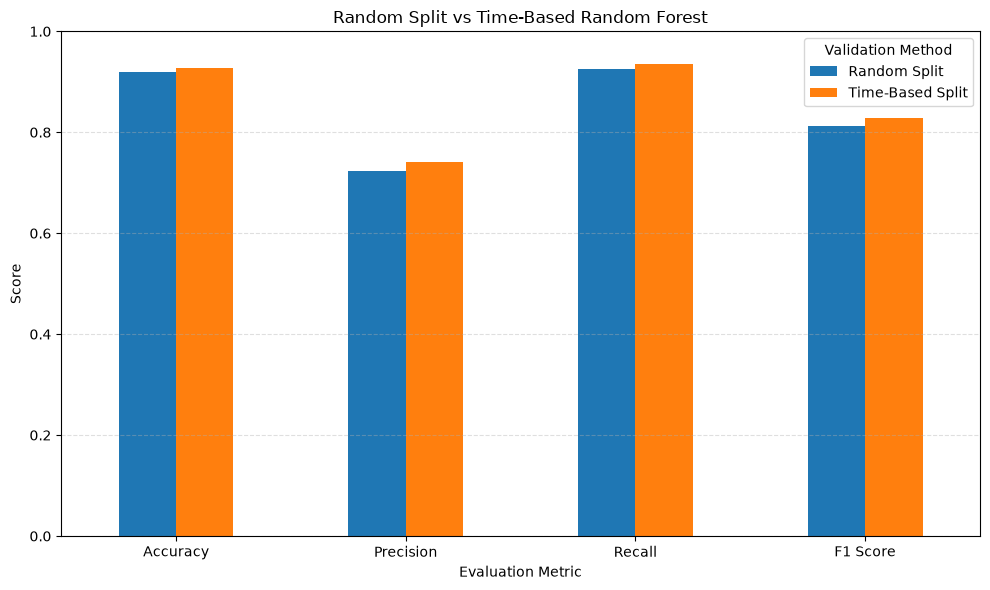

In [335]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Random Split": [0.9200, 0.7238, 0.9251, 0.8122],
    "Time-Based Split": [0.9269, 0.7417, 0.9355, 0.8274]
})

comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Random Split vs Time-Based Random Forest")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Validation Method")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

45. Decision threshold optimisation

In [336]:
# Get probability of an order line being loss-making
y_prob_time = rf_time_model.predict_proba(X_test_time)[:, 1]

# Display first 10 probabilities
print("Predicted probabilities of loss-making:")
print(y_prob_time[:10])

Predicted probabilities of loss-making:
[0.03368801 0.93387557 0.02283865 0.16943354 0.69992018 0.01392317
 0.97423655 0.98509823 0.51101123 0.51559471]


46. Compare different decision thresholds

In [337]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob_time >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test_time, y_pred_threshold),
        "Precision": precision_score(y_test_time, y_pred_threshold),
        "Recall": recall_score(y_test_time, y_pred_threshold),
        "F1 Score": f1_score(y_test_time, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Accuracy  Precision  Recall  F1 Score
       0.3    0.8819     0.6158  0.9823    0.7570
       0.4    0.9143     0.6972  0.9581    0.8071
       0.5    0.9269     0.7417  0.9355    0.8274
       0.6    0.9348     0.8186  0.8371    0.8278
       0.7    0.9450     0.9163  0.7774    0.8412
       0.8    0.9444     0.9823  0.7161    0.8284


### Threshold Optimisation and Precision–Recall Trade-off

The Random Forest model was evaluated using six decision thresholds ranging from 0.30 to 0.80.

The default threshold of 0.50 achieved an F1-score of 82.74%, precision of 74.17%, and recall of 93.55%.

The threshold of 0.70 achieved the highest F1-score of 84.12%, with precision increasing to 91.63%. However, recall decreased to 77.74%, indicating that more actual loss-making order lines were missed.

These findings demonstrate that threshold selection involves balancing false positives against false negatives. A threshold of 0.70 performed best in terms of F1-score in this exploratory comparison, while lower thresholds prioritised the detection of loss-making order lines.

**Methodological limitation:** The threshold comparison used the 2017 test dataset. Therefore, the results are exploratory and should not be considered an unbiased final evaluation. A separate validation period should be used for threshold selection before evaluating the final model on the untouched 2017 test set.

47. Create training and validation datasets

In [338]:
# Split data by time
train_val = df[df["Order Date"].dt.year < 2016].copy()
validation = df[df["Order Date"].dt.year == 2016].copy()

# Training features and target
X_train_val = train_val[features]
y_train_val = train_val["Loss_Making"]

# Validation features and target
X_val = validation[features]
y_val = validation["Loss_Making"]

# Display dataset information
print("TRAINING AND VALIDATION SPLIT")
print("--------------------------------")
print("Training period: 2014–2015")
print("Training rows:", len(X_train_val))

print("\nValidation period: 2016")
print("Validation rows:", len(X_val))

print("\nTraining loss distribution:")
print(y_train_val.value_counts(normalize=True).round(3))

print("\nValidation loss distribution:")
print(y_val.value_counts(normalize=True).round(3))

TRAINING AND VALIDATION SPLIT
--------------------------------
Training period: 2014–2015
Training rows: 4095

Validation period: 2016
Validation rows: 2587

Training loss distribution:
Loss_Making
0    0.811
1    0.189
Name: proportion, dtype: float64

Validation loss distribution:
Loss_Making
0    0.816
1    0.184
Name: proportion, dtype: float64


48. Train the validation model

In [339]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create a new Random Forest pipeline
rf_validation_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using 2014–2015
rf_validation_model.fit(X_train_val, y_train_val)

print("Validation Random Forest trained successfully!")
print("Training data: 2014–2015")
print("Validation data: 2016")

Validation Random Forest trained successfully!
Training data: 2014–2015
Validation data: 2016


49. Generate 2016 validation probabilities

In [340]:
# Predict probabilities for 2016 validation data
y_prob_val = rf_validation_model.predict_proba(X_val)[:, 1]

# Display first 10 predicted probabilities
print("2016 VALIDATION PREDICTION PROBABILITIES")
print("----------------------------------------")
print(y_prob_val[:10])

print("\nTotal validation predictions:", len(y_prob_val))

2016 VALIDATION PREDICTION PROBABILITIES
----------------------------------------
[0.26101065 0.11664436 0.012027   0.08586442 0.02734638 0.15889649
 0.09784083 0.06145145 0.16601033 0.97621754]

Total validation predictions: 2587


50. Compare decision thresholds on 2016

In [341]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

validation_results = []

for threshold in thresholds:

    y_pred_val = (y_prob_val >= threshold).astype(int)

    validation_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_pred_val),
        "Precision": precision_score(y_val, y_pred_val),
        "Recall": recall_score(y_val, y_pred_val),
        "F1 Score": f1_score(y_val, y_pred_val)
    })

validation_df = pd.DataFrame(validation_results)

print("2016 VALIDATION THRESHOLD COMPARISON")
print("------------------------------------")
print(validation_df.round(4).to_string(index=False))

2016 VALIDATION THRESHOLD COMPARISON
------------------------------------
 Threshold  Accuracy  Precision  Recall  F1 Score
       0.3    0.8871     0.6238  0.9769    0.7614
       0.4    0.9099     0.6848  0.9476    0.7951
       0.5    0.9208     0.7361  0.8889    0.8053
       0.6    0.9397     0.8351  0.8386    0.8368
       0.7    0.9459     0.9140  0.7799    0.8416
       0.8    0.9455     0.9641  0.7317    0.8319


### Decision Threshold Selection Using Validation Data

The Random Forest model was trained using 2014–2015 data and evaluated on the 2016 validation dataset. Six classification thresholds, ranging from 0.30 to 0.80, were compared.

The threshold of 0.70 achieved the highest validation F1-score of 84.16%, with precision of 91.40% and recall of 77.99%.

Therefore, a decision threshold of 0.70 was selected for the final model evaluation. This selection was made using validation data, preserving the 2017 dataset for independent final testing.

51. Train the final Random Forest model

In [342]:
# Create the final Random Forest model
final_rf_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using 2014–2016
final_rf_model.fit(X_train_time, y_train_time)

print("FINAL RANDOM FOREST MODEL TRAINED")
print("----------------------------------")
print("Training period: 2014–2016")
print("Training rows:", len(X_train_time))
print("Final test period: 2017")
print("Selected threshold: 0.70")

FINAL RANDOM FOREST MODEL TRAINED
----------------------------------
Training period: 2014–2016
Training rows: 6682
Final test period: 2017
Selected threshold: 0.70


52. Final evaluation on 2017

In [343]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict probabilities on untouched 2017 test data
final_probabilities = final_rf_model.predict_proba(X_test_time)[:, 1]

# Apply the threshold selected using 2016 validation data
selected_threshold = 0.70

final_predictions = (
    final_probabilities >= selected_threshold
).astype(int)

# Evaluate final model
print("FINAL MODEL EVALUATION — 2017")
print("--------------------------------")

print("Selected threshold:", selected_threshold)

print("Accuracy:",
      round(accuracy_score(y_test_time, final_predictions), 4))

print("Precision:",
      round(precision_score(y_test_time, final_predictions), 4))

print("Recall:",
      round(recall_score(y_test_time, final_predictions), 4))

print("F1 Score:",
      round(f1_score(y_test_time, final_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test_time, final_predictions))

print("Confusion Matrix:")
print(confusion_matrix(y_test_time, final_predictions))

FINAL MODEL EVALUATION — 2017
--------------------------------
Selected threshold: 0.7
Accuracy: 0.945
Precision: 0.9163
Recall: 0.7774
F1 Score: 0.8412

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97      2692
           1       0.92      0.78      0.84       620

    accuracy                           0.95      3312
   macro avg       0.93      0.88      0.90      3312
weighted avg       0.94      0.95      0.94      3312

Confusion Matrix:
[[2648   44]
 [ 138  482]]


### Final Random Forest Evaluation on 2017 Data

The final Random Forest model was trained using 6,682 order lines from 2014–2016. A decision threshold of 0.70 was selected using the 2016 validation results.

On the 2017 evaluation dataset, the model achieved:

- Accuracy: 94.50%
- Precision: 91.63%
- Recall: 77.74%
- F1-score: 84.12%

The confusion matrix showed 2,648 true negatives, 482 true positives, 44 false positives and 138 false negatives.

Compared with the default threshold of 0.50, the selected threshold improved precision and F1-score while reducing recall. This indicates that the model became more selective when identifying potentially loss-making order lines.

**Methodological limitation:** Although the final threshold was selected using 2016 validation data, the 2017 threshold results had also been explored earlier in this analysis. Therefore, the 2017 results should be described as a chronological holdout evaluation, not a completely untouched independent test. Further validation on new data would strengthen the findings.

Shap Analysis

1. Prepare the model for SHAP analysis

In [344]:
# Check the chronological preprocessing pipeline
print("Final model:", final_rf_model)

print("\nModel input features:")
print(final_rf_model.feature_names_in_)

print("\nModel preprocessing features:")
print(
    final_rf_model.named_steps["preprocessor"]
    .feature_names_in_
)

print("\nTest data columns:")
print(X_test_time.columns.tolist())

Final model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['Discount', 'Quantity']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Category', 'Sub-Category',
                                                   'Region', 'Segment',
                                                   'Ship Mode'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=12,
                                        min_samples_leaf=4,
                                        min_samples_split=10, n_estimators=200,
                                        n_jobs=-1, random_state=42))])

Model input features:
['Discount' 'Quantity' 'C

In [345]:
from sklearn.base import clone

# Create datasets without Discount
X_train_time_no_discount = X_train_time.drop(columns=["Discount"])
X_test_time_no_discount = X_test_time.drop(columns=["Discount"])

# Create a fresh preprocessing pipeline
preprocessor_time_no_discount = clone(preprocessor)

# Remove Discount from numeric features
preprocessor_time_no_discount = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), ["Quantity"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

print("Training shape:", X_train_time_no_discount.shape)
print("Testing shape:", X_test_time_no_discount.shape)

print("Training columns:", X_train_time_no_discount.columns.tolist())
print("Testing columns:", X_test_time_no_discount.columns.tolist())

Training shape: (6682, 6)
Testing shape: (3312, 6)
Training columns: ['Quantity', 'Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']
Testing columns: ['Quantity', 'Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']


In [346]:
X_train_time_no_discount_transformed = (
    preprocessor_time_no_discount.fit_transform(X_train_time_no_discount)
)

X_test_time_no_discount_transformed = (
    preprocessor_time_no_discount.transform(X_test_time_no_discount)
)

print("Training transformed shape:",
      X_train_time_no_discount_transformed.shape)

print("Testing transformed shape:",
      X_test_time_no_discount_transformed.shape)

Training transformed shape: (6682, 32)
Testing transformed shape: (3312, 32)


In [347]:
from scipy.sparse import issparse

# Extract trained preprocessing component
trained_preprocessor = final_rf_model.named_steps["preprocessor"]

# Extract trained Random Forest classifier
trained_classifier = final_rf_model.named_steps["classifier"]

# Transform 2017 test dataset
X_test_transformed = trained_preprocessor.transform(X_test_time)

# Convert sparse matrix to dense array if necessary
if issparse(X_test_transformed):
    X_test_transformed = X_test_transformed.toarray()

# Get transformed feature names
feature_names = trained_preprocessor.get_feature_names_out()

# Create DataFrame
X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test_time.index
)

print("SHAP DATA PREPARATION COMPLETE")
print("--------------------------------")
print("Original features:", X_test_time.shape[1])
print("Transformed features:", X_test_shap.shape[1])
print("Test samples:", X_test_shap.shape[0])

print("\nFirst 10 transformed features:")
print(feature_names[:10])

SHAP DATA PREPARATION COMPLETE
--------------------------------
Original features: 7
Transformed features: 33
Test samples: 3312

First 10 transformed features:
['num__Discount' 'num__Quantity' 'cat__Category_Furniture'
 'cat__Category_Office Supplies' 'cat__Category_Technology'
 'cat__Sub-Category_Accessories' 'cat__Sub-Category_Appliances'
 'cat__Sub-Category_Art' 'cat__Sub-Category_Binders'
 'cat__Sub-Category_Bookcases']


2. Calculate SHAP values

In [348]:
# Create a reproducible sample of 500 test rows
X_shap_sample = X_test_shap.sample(
    n=500,
    random_state=42
)

# Create SHAP TreeExplainer
explainer = shap.TreeExplainer(trained_classifier)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap_sample)

print("SHAP VALUES CALCULATED SUCCESSFULLY")
print("-----------------------------------")
print("Sample size:", X_shap_sample.shape[0])
print("Number of features:", X_shap_sample.shape[1])
print("SHAP output type:", type(shap_values))

SHAP VALUES CALCULATED SUCCESSFULLY
-----------------------------------
Sample size: 500
Number of features: 33
SHAP output type: <class 'numpy.ndarray'>


3. Inspecting SHAP output

In [349]:
print("SHAP OUTPUT INSPECTION")
print("----------------------")

print("SHAP array shape:", shap_values.shape)
print("Model classes:", trained_classifier.classes_)
print("Expected values:", explainer.expected_value)

SHAP OUTPUT INSPECTION
----------------------
SHAP array shape: (500, 33, 2)
Model classes: [0 1]
Expected values: [0.49895914 0.50104086]


In [350]:
print("SHAP version:", shap.__version__)

print("\nSHAP values type:")
print(type(shap_values))

print("\nSHAP values shape:")
print(np.asarray(shap_values).shape)

print("\nTransformed test data shape:")
print(X_test_transformed.shape)

print("\nFeature names count:")
print(len(trained_preprocessor.get_feature_names_out()))

SHAP version: 0.54.1

SHAP values type:
<class 'numpy.ndarray'>

SHAP values shape:
(500, 33, 2)

Transformed test data shape:
(3312, 33)

Feature names count:
33


In [351]:
from scipy.sparse import issparse

# Preserve the exact 500 observations used in the SHAP calculation
shap_sample_index = X_shap_sample.index.copy()

# Transform the complete chronological test dataset
X_test_shap_full = trained_preprocessor.transform(X_test_time)

# Convert sparse matrix to a dense array if necessary
if issparse(X_test_shap_full):
    X_test_shap_full = X_test_shap_full.toarray()

# Get the encoded feature names
feature_names = trained_preprocessor.get_feature_names_out()

# Create the complete transformed DataFrame
X_test_shap_df = pd.DataFrame(
    X_test_shap_full,
    columns=feature_names,
    index=X_test_time.index
)

# Recover exactly the 500 observations used by SHAP
X_shap_sample = X_test_shap_df.loc[shap_sample_index]

# Extract SHAP values for class 1 (loss-making)
shap_values_loss = shap_values[:, :, 1]

# Create the SHAP DataFrame
shap_df = pd.DataFrame(
    shap_values_loss,
    columns=feature_names,
    index=shap_sample_index
)

print("SHAP sample shape:", X_shap_sample.shape)
print("SHAP values shape:", shap_df.shape)

display(shap_df.head())

SHAP sample shape: (500, 33)
SHAP values shape: (500, 33)


,num__Discount,num__Quantity,cat__Category_Furniture,cat__Category_Office Supplies,cat__Category_Technology,cat__Sub-Category_Accessories,cat__Sub-Category_Appliances,cat__Sub-Category_Art,cat__Sub-Category_Binders,cat__Sub-Category_Bookcases,...,cat__Region_East,cat__Region_South,cat__Region_West,cat__Segment_Consumer,cat__Segment_Corporate,cat__Segment_Home Office,cat__Ship Mode_First Class,cat__Ship Mode_Same Day,cat__Ship Mode_Second Class,cat__Ship Mode_Standard Class
266,-0.124801,-0.002129,-0.034126,-0.034404,-0.001421,-0.007328,0.001691,-0.175639,-0.015163,-0.003294,...,-0.003307,-0.012186,0.006662,-0.003178,-0.001637,0.000100,-0.000080,0.000201,0.001073,0.002349
2280,-0.033214,-0.011045,0.095036,0.040522,0.003691,-0.004483,0.001993,0.011230,0.007594,-0.004651,...,-0.002153,0.005109,-0.020092,0.006116,0.000475,0.002793,0.014430,-0.000096,0.004449,-0.002929
4290,-0.279573,-0.000924,-0.024288,-0.020183,-0.002157,-0.002415,0.000613,-0.084154,-0.017348,-0.002721,...,-0.001827,0.000384,-0.024936,-0.001188,-0.000334,-0.000713,-0.000598,-0.000047,-0.004131,-0.001815
3847,-0.403561,0.002036,-0.020566,-0.009871,0.003090,-0.002502,-0.001353,0.010169,-0.017193,-0.002235,...,-0.000865,0.000240,0.014106,-0.003351,-0.000968,-0.005479,0.000511,-0.000147,-0.005911,-0.005955
750,-0.428876,-0.010288,0.032892,0.009067,0.002011,-0.004028,0.000181,0.006888,-0.013410,-0.004584,...,0.000218,0.003312,0.010761,0.001100,-0.001250,-0.000127,-0.001141,-0.000786,-0.001339,-0.001850


4. Create the global SHAP feature importance plot

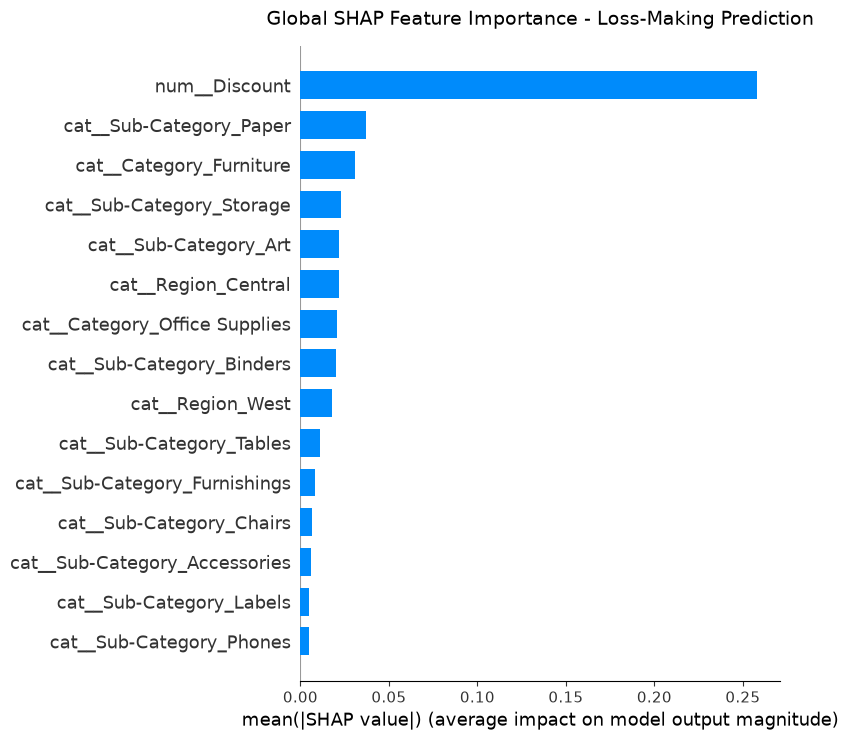

In [352]:
# Select SHAP values for class 1 (loss-making)
shap_values_loss = shap_values[:, :, 1]

# Create the SHAP bar chart without displaying it immediately
shap.summary_plot(
    shap_values_loss,
    X_shap_sample,
    plot_type="bar",
    max_display=15,
    show=False
)

# Add title to the same figure
plt.title(
    "Global SHAP Feature Importance - Loss-Making Prediction",
    fontsize=14,
    pad=15
)

plt.tight_layout()
plt.show()

5. Create the SHAP beeswarm plot

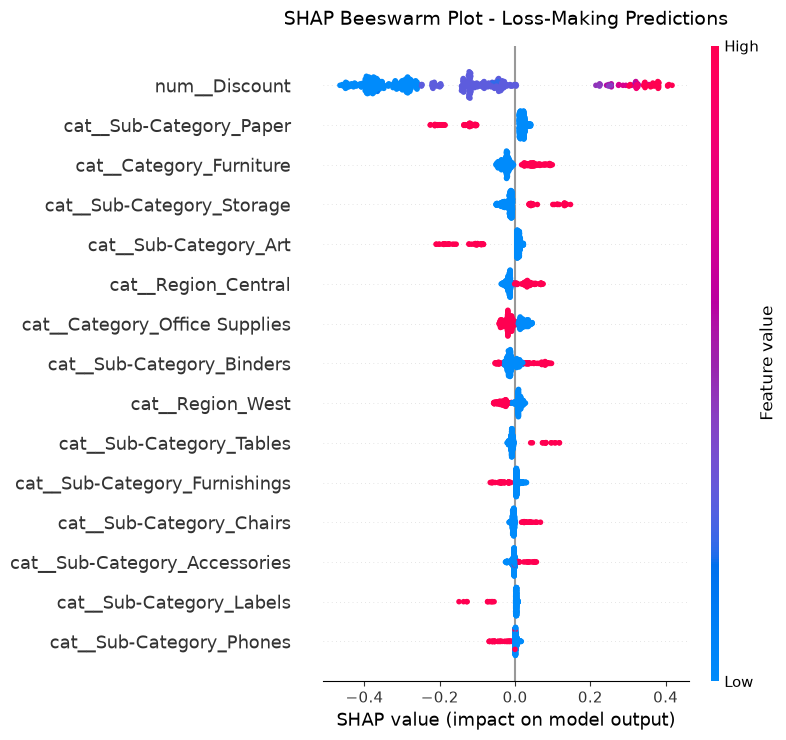

In [353]:
# Create SHAP beeswarm plot for loss-making class
shap.summary_plot(
    shap_values_loss,
    X_shap_sample,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Beeswarm Plot - Loss-Making Predictions",
    fontsize=14,
    pad=15
)

plt.tight_layout()
plt.show()

6. Investigate the effect of discount on individual predictions

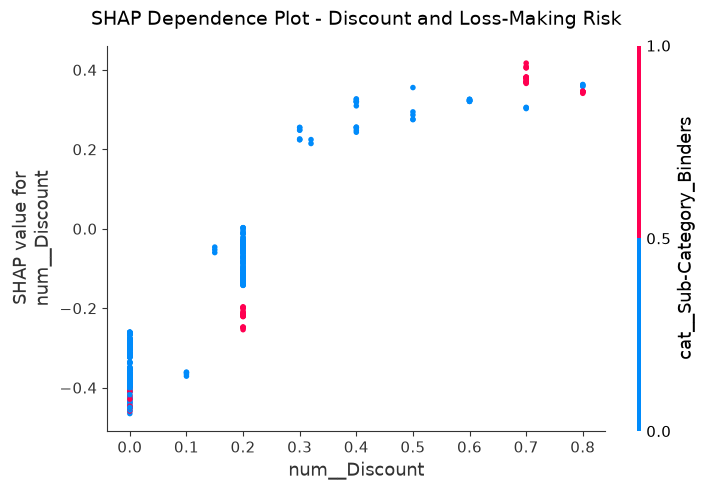

In [354]:
# SHAP dependence plot for Discount
shap.dependence_plot(
    "num__Discount",
    shap_values_loss,
    X_shap_sample,
    interaction_index="auto",
    show=False
)

plt.title(
    "SHAP Dependence Plot - Discount and Loss-Making Risk",
    fontsize=14,
    pad=15
)

plt.tight_layout()
plt.show()

7. Quantify the discount relationship

In [355]:
# Combine discount values with their SHAP contributions
discount_shap = pd.DataFrame({
    "Discount": X_shap_sample["num__Discount"].values,
    "SHAP_Value": shap_values_loss[
        :,
        X_shap_sample.columns.get_loc("num__Discount")
    ]
})

# Calculate mean SHAP contribution at each discount level
discount_shap_summary = (
    discount_shap
    .groupby("Discount")["SHAP_Value"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

print("DISCOUNT VS SHAP CONTRIBUTION")
print("--------------------------------")
display(discount_shap_summary.round(4))

DISCOUNT VS SHAP CONTRIBUTION
--------------------------------


,Discount,count,mean,std
0,0.00,245,-0.3510,0.0546
1,0.10,4,-0.3649,0.0046
2,0.15,3,-0.0529,0.0069
3,0.20,176,-0.1017,0.0596
4,0.30,7,0.2402,0.0146
5,0.32,2,0.2196,0.0070
6,0.40,11,0.2889,0.0365
7,0.50,5,0.2974,0.0335
8,0.60,10,0.3231,0.0020
9,0.70,24,0.3724,0.0296


The SHAP dependence analysis identified a pronounced nonlinear relationship between discount levels and predicted loss-making risk. Mean SHAP contributions were negative at discount levels up to 20%, but became positive at 30%. The contribution generally increased at higher discount levels, reaching its highest observed mean at 70%. These findings indicate that the trained Random Forest associates higher discounts with increased loss-making predictions. However, unequal sample sizes across discount levels require cautious interpretation, and the observed transition should not be interpreted as a causal or universal business threshold.

8. Investigate discount and Binders interaction

In [356]:
# Identify the Binders feature
binders_column = "cat__Sub-Category_Binders"

# Combine discount, Binders indicator and SHAP contribution
binders_shap = pd.DataFrame({
    "Discount": X_shap_sample["num__Discount"].values,
    "Binders": X_shap_sample[binders_column].values,
    "SHAP_Value": shap_values_loss[
        :,
        X_shap_sample.columns.get_loc("num__Discount")
    ]
})

# Compare mean discount SHAP contribution
# between Binders and non-Binders
binders_comparison = (
    binders_shap
    .groupby(["Discount", "Binders"])["SHAP_Value"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

binders_comparison["Product_Type"] = (
    binders_comparison["Binders"]
    .map({0: "Non-Binders", 1: "Binders"})
)

print("DISCOUNT SHAP CONTRIBUTION: BINDERS VS NON-BINDERS")
print("--------------------------------------------------")

display(
    binders_comparison[
        ["Discount", "Product_Type", "count", "mean", "std"]
    ].round(4)
)

DISCOUNT SHAP CONTRIBUTION: BINDERS VS NON-BINDERS
--------------------------------------------------


,Discount,Product_Type,count,mean,std
0,0.00,Non-Binders,224,-0.3439,0.0511
1,0.00,Binders,21,-0.4272,0.0224
2,0.10,Non-Binders,4,-0.3649,0.0046
3,0.15,Non-Binders,3,-0.0529,0.0069
4,0.20,Non-Binders,154,-0.0848,0.0416
5,0.20,Binders,22,-0.2196,0.0183
6,0.30,Non-Binders,7,0.2402,0.0146
7,0.32,Non-Binders,2,0.2196,0.0070
8,0.40,Non-Binders,11,0.2889,0.0365
9,0.50,Non-Binders,5,0.2974,0.0335


9. Test the interaction more formally

In [357]:
# Calculate SHAP interaction values
interaction_explainer = shap.TreeExplainer(
    trained_classifier
)

interaction_values = interaction_explainer.shap_interaction_values(
    X_shap_sample
)

print("SHAP INTERACTION ANALYSIS")
print("-------------------------")
print("Output type:", type(interaction_values))
print("Output shape:", np.array(interaction_values).shape)

SHAP INTERACTION ANALYSIS
-------------------------
Output type: <class 'numpy.ndarray'>
Output shape: (500, 33, 33, 2)


10. Measure the Discount–Binders interaction

In [358]:
# Select interaction values for loss-making class (class 1)
interaction_loss = interaction_values[:, :, :, 1]

# Identify feature positions
discount_idx = X_shap_sample.columns.get_loc("num__Discount")
binders_idx = X_shap_sample.columns.get_loc("cat__Sub-Category_Binders")

# Extract Discount-Binders interaction values
discount_binders_interaction = interaction_loss[
    :, discount_idx, binders_idx
]

# Calculate interaction statistics
print("DISCOUNT–BINDERS SHAP INTERACTION")
print("---------------------------------")
print("Mean interaction:",
      round(np.mean(discount_binders_interaction), 6))

print("Mean absolute interaction:",
      round(np.mean(np.abs(discount_binders_interaction)), 6))

print("Standard deviation:",
      round(np.std(discount_binders_interaction), 6))

print("Minimum:",
      round(np.min(discount_binders_interaction), 6))

print("Maximum:",
      round(np.max(discount_binders_interaction), 6))

DISCOUNT–BINDERS SHAP INTERACTION
---------------------------------
Mean interaction: 0.010603
Mean absolute interaction: 0.0225
Standard deviation: 0.02819
Minimum: -0.115655
Maximum: 0.042085


11. Compare the strongest feature interactions

In [359]:
# Average absolute interaction values across observations
# for loss-making class
mean_interactions = np.abs(interaction_loss).mean(axis=0)

# Remove diagonal (main effects)
np.fill_diagonal(mean_interactions, 0)

# Extract feature names
feature_names = X_shap_sample.columns.tolist()

# Create a table of unique feature pairs
interaction_pairs = []

for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):
        interaction_pairs.append({
            "Feature 1": feature_names[i],
            "Feature 2": feature_names[j],
            "Mean Absolute Interaction": mean_interactions[i, j]
        })

# Sort and display the top 15 pairs
interaction_ranking = (
    pd.DataFrame(interaction_pairs)
    .sort_values(
        "Mean Absolute Interaction",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP 15 SHAP FEATURE INTERACTIONS")
print("--------------------------------")

display(interaction_ranking.head(15).round(5))

TOP 15 SHAP FEATURE INTERACTIONS
--------------------------------


,Feature 1,Feature 2,Mean Absolute Interaction
0,num__Discount,cat__Sub-Category_Binders,0.02250
1,num__Discount,cat__Sub-Category_Paper,0.01116
2,num__Discount,cat__Sub-Category_Storage,0.01047
3,num__Discount,cat__Region_West,0.00977
4,num__Discount,cat__Category_Furniture,0.00876
5,num__Discount,cat__Region_Central,0.00876
6,num__Discount,cat__Category_Office Supplies,0.00710
7,num__Discount,cat__Sub-Category_Art,0.00615
8,cat__Category_Furniture,cat__Sub-Category_Furnishings,0.00433
9,cat__Category_Office Supplies,cat__Sub-Category_Storage,0.00407


12. Visualise the Discount–Binders interaction

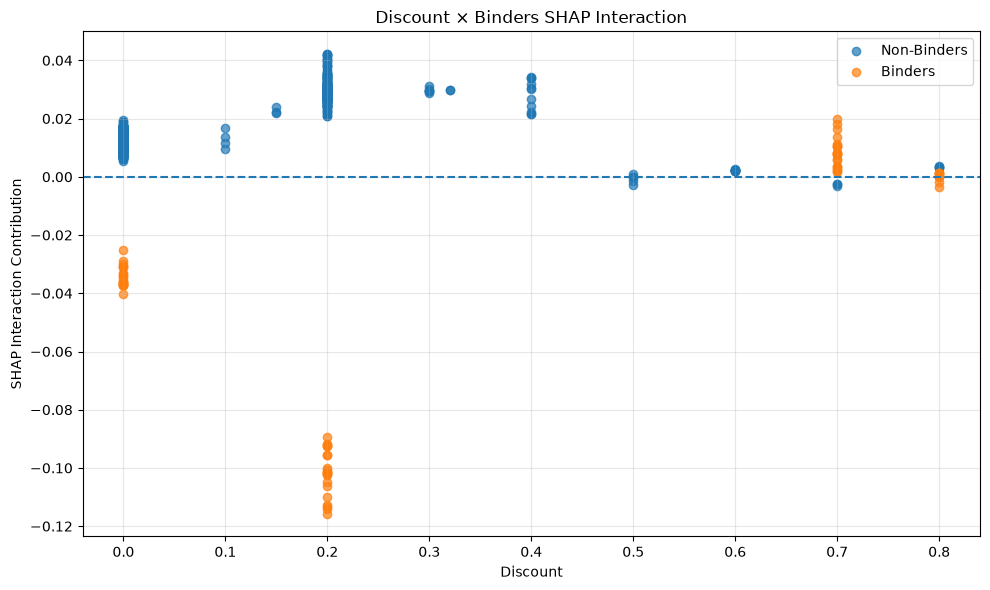

In [360]:
# Extract interaction contributions for Discount and Binders
interaction_df = pd.DataFrame({
    "Discount": X_shap_sample["num__Discount"].values,
    "Binders": X_shap_sample["cat__Sub-Category_Binders"].values,
    "Interaction": discount_binders_interaction
})

# Plot interaction contributions
plt.figure(figsize=(10, 6))

for value, label in [(0, "Non-Binders"), (1, "Binders")]:
    subset = interaction_df[interaction_df["Binders"] == value]

    plt.scatter(
        subset["Discount"],
        subset["Interaction"],
        alpha=0.7,
        label=label
    )

plt.axhline(0, linestyle="--")
plt.xlabel("Discount")
plt.ylabel("SHAP Interaction Contribution")
plt.title("Discount × Binders SHAP Interaction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

SHAP interaction analysis identified a potentially meaningful interaction between discount level and the Binders sub-category. At discount levels of 0% and 20%, the interaction contribution differed substantially between Binders and non-Binders observations. In particular, Binders exhibited strongly negative interaction contributions at a 20% discount, whereas non-Binders observations generally showed positive contributions. At higher discount levels, the interaction contributions for both groups were closer to zero.

These findings indicate that the Random Forest model does not treat discount as having a uniform contribution across all product sub-categories. The relationship between discount and predicted loss-making risk appears to depend partly on product sub-category. However, this is a model-specific interaction rather than evidence of a causal relationship. The number of observations at some discount levels is limited, so the pattern should be interpreted cautiously.

13. check whether the pattern appears in actual outcomes

In [361]:
# Compare actual loss-making rates for Binders and non-Binders
# using the complete 2017 test set

validation_df = df.loc[X_test_time.index].copy()

validation_df["Product Group"] = np.where(
    validation_df["Sub-Category"] == "Binders",
    "Binders",
    "Non-Binders"
)

validation_df["Loss_Making"] = (
    validation_df["Profit"] < 0
).astype(int)

actual_interaction_check = (
    validation_df
    .groupby(["Discount", "Product Group"])
    .agg(
        Order_Lines=("Loss_Making", "size"),
        Loss_Making_Rate=("Loss_Making", "mean"),
        Average_Profit=("Profit", "mean")
    )
    .reset_index()
)

actual_interaction_check["Loss_Making_Rate"] *= 100

display(
    actual_interaction_check
    .sort_values(["Discount", "Product Group"])
    .round(2)
)

,Discount,Product Group,Order_Lines,Loss_Making_Rate,Average_Profit
0,0.00,Binders,107,0.00,108.11
1,0.00,Non-Binders,1483,0.00,62.43
2,0.10,Non-Binders,28,7.14,117.88
3,0.15,Non-Binders,16,31.25,33.60
4,0.20,Binders,188,0.00,63.31
5,0.20,Non-Binders,1035,16.33,20.40
6,0.30,Non-Binders,68,98.53,-56.88
7,0.32,Non-Binders,11,100.00,-44.75
8,0.40,Non-Binders,69,85.51,-113.52
9,0.45,Non-Binders,4,100.00,-307.11


The actual outcome analysis provides additional context for the SHAP interaction findings. At a 20% discount, Binders recorded no loss-making observations across 188 order lines, with an average profit of $63.31. In contrast, non-Binders recorded a loss-making rate of 16.33% across 1,035 order lines, with an average profit of $20.40. At zero discount, both groups also recorded no loss-making observations.

At higher discount levels, substantial losses were observed. All Binders observations at 70% and 80% discounts were loss-making. These results suggest that profitability patterns vary across discount levels and product sub-categories. However, the SHAP interaction values describe the fitted model's learned relationships, not causal effects. The aggregated non-Binders group, uneven sample sizes and missing product-group comparisons at certain discount levels limit the conclusions that can be drawn.

actual loss-making rates for Binders and non-Binders across discount levels.

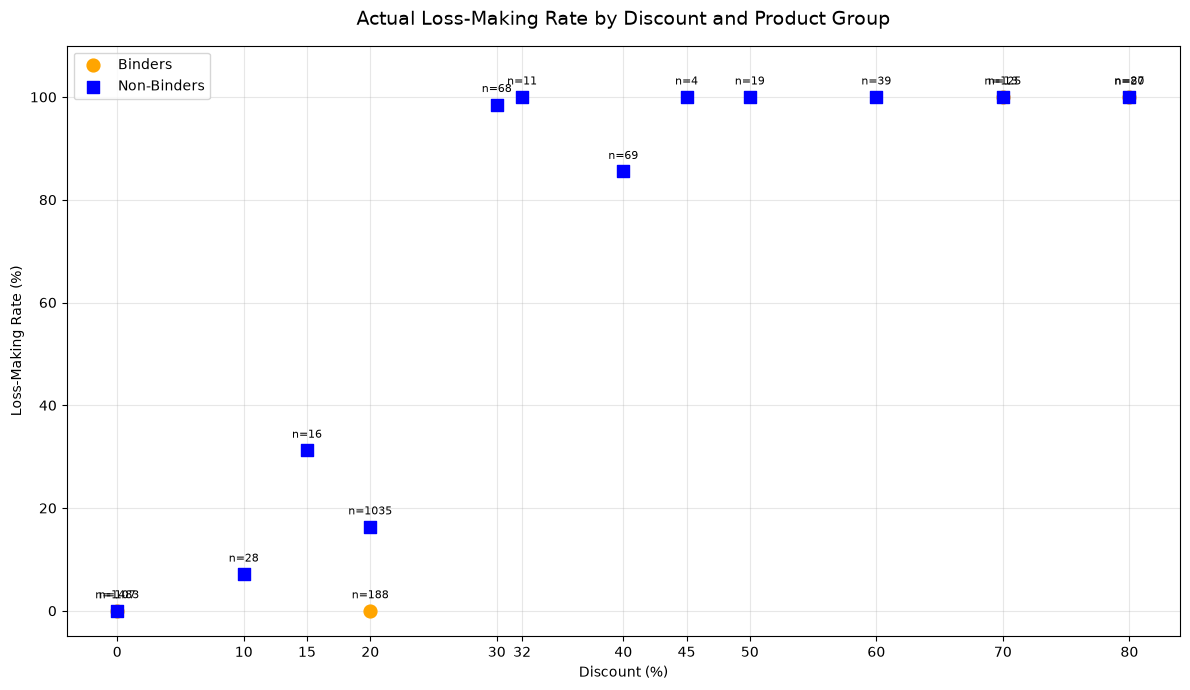

In [362]:
# Actual loss-making rate by discount
# Markers only: no misleading interpolation

plt.figure(figsize=(12, 7))

for group, color, marker in [
    ("Binders", "orange", "o"),
    ("Non-Binders", "blue", "s")
]:
    subset = actual_interaction_check[
        actual_interaction_check["Product Group"] == group
    ].sort_values("Discount")

    plt.scatter(
        subset["Discount"] * 100,
        subset["Loss_Making_Rate"],
        label=group,
        color=color,
        marker=marker,
        s=85,
        zorder=3
    )

    for _, row in subset.iterrows():
        plt.annotate(
            f"n={int(row['Order_Lines'])}",
            (row["Discount"] * 100, row["Loss_Making_Rate"]),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

plt.title(
    "Actual Loss-Making Rate by Discount and Product Group",
    fontsize=14,
    pad=15
)
plt.xlabel("Discount (%)")
plt.ylabel("Loss-Making Rate (%)")
plt.xticks(sorted(actual_interaction_check["Discount"].unique() * 100))
plt.ylim(-5, 110)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

The analysis of actual loss-making rates across discount levels revealed substantial differences between product groups. At a 20% discount, Binders recorded no loss-making observations across 188 order lines, compared with a 16.33% loss-making rate among non-Binders across 1,035 lines. For non-Binders, the loss-making rate increased to 98.53% at a 30% discount and remained consistently high at larger discounts. A reduction to 85.51% was observed at 40%, demonstrating that the relationship was not perfectly monotonic.

Binders also recorded a 100% loss-making rate at 70% and 80% discounts. However, no Binders observations were available between 20% and 70%. Consequently, the results suggest differences in discount-related profitability patterns across product groups, but do not establish a universal discount threshold or a causal relationship.

# 10. Results and Discussion

## 10.1 Overview of Key Findings

This section presents the key findings from the exploratory data analysis,
customer and regional analysis, discount analysis, and predictive modelling.

The analysis focuses on identifying sales and profitability patterns,
understanding factors associated with loss-making transactions, and evaluating
the ability of machine learning models to identify potentially unprofitable
order lines.

## 10.2 Overall Business Performance

## 10.3 Product and Category Profitability

## 10.4 Customer and Regional Performance

## 10.5 Discount and Profitability Analysis

## 10.6 Predictive Modelling Results

## 10.7 SHAP Explainability and Interaction Analysis

## 10.8 Business Recommendations

## 10.9 Limitations of the Analysis

Overall Business Performance using the actual dataset results.
## 10.2 Overall Business Performance

The Superstore dataset contains 9,994 order-line records covering the period
from 2014 to 2017. The business generated total sales of $2,297,200.86 and
overall profit of $286,397.02.

The analysis identified 5,009 unique orders and 793 unique customers.
A total of 37,873 units were sold during the observation period.

### Key Performance Indicators

| Performance Metric | Result |
|---|---:|
| Total Sales | $2,297,200.86 |
| Total Profit | $286,397.02 |
| Unique Orders | 5,009 |
| Unique Customers | 793 |
| Total Quantity Sold | 37,873 |
| Average Profit Margin | 12.47% |

The overall profit margin was approximately 12.47%, calculated as total profit
divided by total sales.

### Yearly Performance

Sales increased considerably over the four-year observation period.
Although sales declined slightly in 2015, the business experienced substantial
growth in 2016 and 2017.

| Year | Total Sales | Total Profit |
|---|---:|---:|
| 2014 | $484,247.50 | $49,543.97 |
| 2015 | $470,532.51 | $61,618.60 |
| 2016 | $609,205.60 | $81,795.17 |
| 2017 | $733,215.26 | $93,439.27 |

Sales increased by approximately 29.47% in 2016 and 20.36% in 2017.
Profit also increased throughout the period, reaching its highest value in 2017.

However, the profit margin declined from approximately 13.43% in 2016
to 12.74% in 2017. This indicates that sales growth did not translate
into an equivalent increase in profitability.

### Discussion

Overall, the business demonstrated positive financial performance and
consistent growth in total profit. Nevertheless, the reduction in profit
margin during 2017 highlights the importance of monitoring profitability
alongside revenue growth.

Further investigation of product categories, discount strategies and
regional performance can help identify areas where profitability may
be improved.

Product and Category Profitability.
## 10.3 Product and Category Profitability

The category-level analysis revealed differences in revenue generation
and profitability across the three main product categories.

### Category Performance

| Category | Total Sales | Total Profit | Profit Margin |
|---|---:|---:|---:|
| Technology | $836,154.03 | $145,454.95 | 17.40% |
| Office Supplies | $719,047.03 | $122,490.80 | 17.04% |
| Furniture | $741,999.80 | $18,451.27 | 2.49% |

Technology generated the highest sales and profit, with a profit margin
of approximately 17.40%. Office Supplies also demonstrated strong
profitability, achieving a margin of 17.04%.

Furniture generated substantial revenue but achieved a considerably
lower profit margin of only 2.49%. This suggests that revenue generation
alone does not necessarily indicate strong financial performance.

### Sub-Category Profitability

The sub-category analysis provided a more detailed understanding
of product-level profitability.

The five most profitable sub-categories were:

| Sub-Category | Total Profit |
|---|---:|
| Copiers | $55,617.82 |
| Phones | $44,515.73 |
| Accessories | $41,936.64 |
| Paper | $34,053.57 |
| Binders | $30,221.76 |

Copiers generated the highest total profit, followed by Phones
and Accessories.

In contrast, the five weakest sub-categories by total profit were:

| Sub-Category | Total Profit |
|---|---:|
| Tables | -$17,725.48 |
| Bookcases | -$3,472.56 |
| Supplies | -$1,189.10 |
| Fasteners | $949.52 |
| Labels | $5,546.25 |

Tables recorded the largest overall loss, while Bookcases and Supplies
also generated negative profit.

### Discussion

The findings indicate that profitability varies substantially
between product categories and sub-categories.

Technology and Office Supplies represent stronger profit-generating
categories, whereas Furniture requires closer examination.

At the sub-category level, Tables and Bookcases deserve particular
attention because their cumulative losses may reduce overall business
profitability.

These findings support the need for product-level profitability
monitoring rather than relying exclusively on sales revenue.

Customer and Regional Performance.
**## 10.4 Customer and Regional Performance**

The customer and regional analyses were conducted to understand
which customer segments and geographical regions contribute most
to business sales and profitability.

**### Customer Performance**

The analysis identified 793 unique customers. The highest-revenue
customer was Sean Miller, generating total sales of $25,043.05.
However, this customer recorded a negative total profit of -$1,980.74.

Tamara Chand generated sales of $19,052.22 and achieved a profit
of $8,981.32, making this customer the most profitable among the
top-sales customers.

This demonstrates that customers generating high sales do not
necessarily generate high profits.

Six customers appeared in both the top 10 sales and top 10 profit
rankings: Tamara Chand, Raymond Buch, Sanjit Chand, Hunter Lopez,
Adrian Barton and Tom Ashbrook.

**### Customer Segment Performance**

| Customer Segment | Total Sales | Total Profit | Profit Margin |
|---|---:|---:|---:|
| Consumer | $1,161,401.34 | $134,119.21 | 11.55% |
| Corporate | $706,146.37 | $91,979.13 | 13.03% |
| Home Office | $429,653.15 | $60,298.68 | 14.03% |

The Consumer segment generated the highest sales and total profit.
However, Home Office achieved the highest profit margin at 14.03%,
followed by Corporate at 13.03%.

This indicates that although Consumer customers contribute the
largest overall revenue, Home Office customers generate a higher
profit relative to their sales.

**### Regional Performance**

| Region | Total Sales | Total Profit | Profit Margin |
|---|---:|---:|---:|
| West | $725,457.82 | $108,418.45 | 14.94% |
| East | $678,781.24 | $91,522.78 | 13.48% |
| Central | $501,239.89 | $39,706.36 | 7.92% |
| South | $391,721.90 | $46,749.43 | 11.93% |

The West region achieved the highest sales, total profit and profit
margin. The East region also demonstrated strong financial performance.

In contrast, the Central region recorded the lowest profit margin
at 7.92%, despite generating more sales than the South region.

The West and East regions together contributed approximately 61%
of total sales and 70% of total profit.

**### Discussion**

The findings reveal differences in customer value and regional
profitability.

The Consumer segment is the largest contributor to total sales,
while Home Office achieves the strongest profit margin. This suggests
that customer acquisition and retention strategies should consider
profitability as well as revenue.

Geographically, the West and East regions demonstrate stronger
profitability. The Central region requires further investigation,
particularly into its product mix and discount patterns.

Overall, customer and regional performance should be evaluated
using both sales and profit indicators rather than revenue alone.

Discount and Profitability Analysis.
**## 10.5 Discount and Profitability Analysis**

The discount analysis investigated the relationship between discount
levels and business profitability. The objective was to identify
discount patterns associated with positive and negative profit.

**### Discount Performance by Category**

| Category | Average Discount | Total Sales | Total Profit | Profit Margin |
|---|---:|---:|---:|---:|
| Furniture | 17.40% | $741,999.80 | $18,451.27 | 2.49% |
| Office Supplies | 15.70% | $719,047.03 | $122,490.80 | 17.04% |
| Technology | 13.20% | $836,154.03 | $145,454.95 | 17.40% |

Furniture recorded the highest average discount at approximately
17.40%, while also achieving the lowest profit margin of 2.49%.

Technology had the lowest average discount and the highest profit
margin. Office Supplies also demonstrated strong profitability.

These observations indicate an association between discount patterns
and category-level profitability. However, they do not establish that
higher discounts alone caused lower profit.

**### Profitability Across Discount Levels**

The transaction-level analysis revealed substantial differences
in profitability across discount levels.

| Discount | Order Lines | Total Profit | Mean Profit per Line |
|---|---:|---:|---:|
| 0% | 4,798 | $320,987.60 | $66.90 |
| 10% | 94 | $9,029.18 | $96.06 |
| 15% | 52 | $1,418.99 | $27.29 |
| 20% | 3,657 | $90,337.31 | $24.70 |
| 30% | 227 | -$10,369.28 | -$45.68 |
| 32% | 27 | -$2,391.14 | -$88.56 |
| 40% | 206 | -$23,057.05 | -$111.93 |
| 45% | 11 | -$2,493.11 | -$226.65 |
| 50% | 66 | -$20,506.43 | -$310.70 |
| 60% | 138 | -$5,944.66 | -$43.08 |
| 70% | 418 | -$40,075.36 | -$95.87 |
| 80% | 300 | -$30,539.04 | -$101.80 |

The results show that discount levels of 0% to 20% were associated
with positive total profit, whereas discount levels of 30% and above
recorded negative total profit.

The largest total loss occurred at a 70% discount, reaching
-$40,075.36 across 418 order lines.

The 10% discount group recorded the highest mean profit per line,
although its sample size was considerably smaller than those of
the 0% and 20% groups.

**### Discount and Product Sub-Category Investigation**

Further investigation identified products that repeatedly generated
negative profit.

The Cubify CubeX 3D Printer Double Head Print recorded the largest
product-level loss of -$8,879.97. Other products with substantial
losses included the Lexmark MX611dhe Monochrome Laser Printer and
Cubify CubeX 3D Printer Triple Head Print.

Furniture products, particularly Tables, also appeared frequently
among the loss-making products.

Some products generated positive profit at lower discounts but
negative profit at higher discounts. However, this was not consistent
for every product. For example, the Martin Yale Chadless Opener
Electric Letter Opener recorded a negative total profit despite
an average discount of only 10%.

This suggests that discount levels are not the only factor associated
with product profitability.

**### Discussion**

The analysis demonstrates that discount management is an important
area for profitability monitoring.

Higher discount levels were frequently associated with negative
profit, particularly at discounts of 30% and above. However, product
type and other transaction characteristics also appear relevant.

The findings support the use of product-level discount monitoring,
profitability checks and targeted pricing strategies rather than
applying uniform discount policies across all products.

Predictive Modelling Results.
**## 10.6 Predictive Modelling Results**

Machine learning was applied to predict whether an order line would
generate a positive or negative profit. The prediction task was
formulated as a binary classification problem.

**### Target Variable**

A binary target variable named `Loss_Making` was created using the
following definition:

- Class 0: Non-loss-making order lines (Profit >= 0).
- Class 1: Loss-making order lines (Profit < 0).

The dataset contained 8,123 non-loss-making observations and
1,871 loss-making observations.

This represents approximately 81.28% non-loss-making observations
and 18.72% loss-making observations.

**### Feature Selection and Preprocessing**

The following seven input features were selected:

| Feature | Description |
|---|---|
| Discount | Discount applied to the order line |
| Quantity | Number of units purchased |
| Category | Main product category |
| Sub-Category | Specific product sub-category |
| Region | Geographical sales region |
| Segment | Customer segment |
| Ship Mode | Shipping method |

Profit and Sales were excluded from the input features to avoid
direct target leakage.

Numerical variables were processed using median imputation,
while categorical variables were transformed using one-hot encoding.

**### Model Training and Validation**

A Random Forest Classifier was selected because it can capture
non-linear relationships and interactions between input features.

The data was divided chronologically:

- Training dataset: 2014–2016 (6,682 observations).
- Testing dataset: 2017 (3,312 observations).

The chronological split provides a more realistic evaluation of
the model's ability to predict outcomes for a later period.

The model used 200 decision trees, a maximum depth of 12,
minimum split size of 10 and minimum leaf size of 4.
Class weighting was also applied to address class imbalance.

**### Decision Threshold Optimisation**

The default classification threshold of 0.50 was not automatically
assumed to be optimal.

A validation dataset from 2016 was used to compare alternative
classification thresholds. A threshold of 0.70 achieved the
highest validation F1-score of approximately 0.8416.

The final model was trained using 2014–2016 data and evaluated
on the 2017 test dataset using the selected threshold of 0.70.

**### Final Model Performance**

| Evaluation Metric | Result |
|---|---:|
| Accuracy | 94.50% |
| Precision (Loss-Making) | 91.63% |
| Recall (Loss-Making) | 77.74% |
| F1-Score (Loss-Making) | 84.12% |

The confusion matrix was:

| Actual / Predicted | Non-Loss-Making | Loss-Making |
|---|---:|---:|
| Non-Loss-Making | 2,648 | 44 |
| Loss-Making | 138 | 482 |

The model correctly identified 482 loss-making observations and
2,648 non-loss-making observations.

It also produced 44 false positives and 138 false negatives.

**### Discussion**

The Random Forest model achieved an accuracy of 94.50% and an
F1-score of 84.12% for the loss-making class on the chronological
2017 test dataset.

The precision of 91.63% indicates that most observations predicted
as loss-making were actually loss-making.

The recall of 77.74% indicates that the model identified approximately
78% of all actual loss-making observations, while some loss-making
cases remained undetected.

The selected threshold prioritised a stronger balance between
precision and recall, with fewer false positives than the default
0.50 threshold.

Overall, the results suggest that Random Forest can provide useful
risk predictions for identifying potentially unprofitable order lines.
However, its predictions should support rather than replace business
and pricing decisions.

SHAP Explainability and Interaction Analysis.
**## 10.7 SHAP Explainability and Interaction Analysis**

SHAP (SHapley Additive exPlanations) was used to interpret the
predictions generated by the trained Random Forest model.

The purpose of this analysis was to identify the features that
contributed most strongly to the model's loss-making predictions
and investigate potential interactions between discount levels
and product characteristics.

SHAP analysis was performed on a sample of 500 observations
from the 2017 test dataset.

**### Global Feature Importance**

The SHAP global importance analysis identified Discount as
the most influential feature in the model's loss-making predictions.

Sub-category and category indicators also contributed to the
model's predictions.

The most influential features included:

1. Discount
2. Sub-Category: Paper
3. Category: Furniture
4. Sub-Category: Storage
5. Sub-Category: Art
6. Region: Central
7. Category: Office Supplies
8. Sub-Category: Binders
9. Region: West
10. Sub-Category: Tables

Discount had substantially higher mean absolute SHAP importance
than the other individual encoded features.

This indicates that the model relied heavily on discount information
when distinguishing between loss-making and non-loss-making
order lines.

**### SHAP Beeswarm Analysis**

The SHAP beeswarm plot provided information about both the magnitude
and direction of feature contributions.

Higher discount values generally contributed towards higher
loss-making predictions, while lower discount values generally
contributed in the opposite direction.

Several product sub-categories showed different contribution
patterns. Furniture, Storage and Tables frequently contributed
towards loss-making predictions, while Paper and Art often
contributed in the opposite direction.

These patterns describe the behaviour of the trained model and
should not be interpreted as causal relationships.

**### Discount Dependence Analysis**

The SHAP dependence plot demonstrated a non-linear relationship
between discount and the model's predicted loss-making risk.

Lower discount values generally produced negative SHAP contributions,
whereas higher discount values generally produced positive
contributions.

A noticeable change in the contribution pattern appeared between
20% and 30% discount.

This suggests that the model learned a non-linear relationship
between discount and loss-making predictions rather than a simple
linear relationship.

However, this pattern does not establish a universal profitability
threshold or prove that increasing discounts directly causes losses.

**### SHAP Interaction Analysis**

SHAP interaction values were calculated to investigate whether
the contribution of discount varied according to product
characteristics.

The strongest interaction identified was:

- Discount × Sub-Category: Binders (0.02250)
- Discount × Sub-Category: Paper (0.01116)
- Discount × Sub-Category: Storage (0.01047)
- Discount × Region: West (0.00977)
- Discount × Category: Furniture (0.00876)

The results suggest that the model's treatment of discount
depends partly on other features, particularly product
sub-categories.

**### Discount and Binders Investigation**

A more detailed investigation of the Discount × Binders interaction
revealed different SHAP interaction contributions for Binders
and non-Binders observations.

At 0% and 20% discount, the interaction contribution for Binders
was negative, whereas non-Binders generally showed positive
interaction contributions.

The difference was particularly noticeable at a 20% discount.

To provide additional context, actual outcomes from the 2017
test dataset were examined.

| Discount | Product Group | Order Lines | Loss-Making Rate |
|---|---|---:|---:|
| 0% | Binders | 107 | 0% |
| 0% | Non-Binders | 1,483 | 0% |
| 20% | Binders | 188 | 0% |
| 20% | Non-Binders | 1,035 | 16.33% |
| 70% | Binders | 125 | 100% |
| 70% | Non-Binders | 13 | 100% |
| 80% | Binders | 80 | 100% |
| 80% | Non-Binders | 27 | 100% |

At a 20% discount, Binders recorded no loss-making observations,
while non-Binders recorded a loss-making rate of 16.33%.

At 70% and 80% discounts, all observed order lines in both groups
were loss-making.

However, there were no Binders observations between 20% and 70%.
Consequently, the analysis cannot establish the exact discount
level at which Binders profitability deteriorates.

**### Discussion**

The SHAP analysis provides an interpretable view of the Random
Forest model's decision-making behaviour.

Discount emerged as the dominant feature, while product sub-category
and regional indicators also contributed to the predictions.

The interaction analysis further suggests that discount-related
prediction patterns vary across product groups.

The comparison with actual outcomes provides additional evidence
that profitability patterns differ between Binders and non-Binders
at certain observed discount levels.

Nevertheless, SHAP values explain model behaviour rather than
causal effects. The interaction findings should therefore be
interpreted as model-specific relationships requiring further
investigation.

Business Recommendations.
**## 10.8 Business Recommendations**

Based on the exploratory data analysis, profitability investigation,
predictive modelling and SHAP explainability results, several
recommendations can be made to improve business performance.

**### 1. Introduce Discount Control Policies**

The analysis identified a strong association between higher
discount levels and negative profitability.

Discount levels of 30% and above frequently recorded negative
total profit.

The business should introduce discount approval procedures,
particularly for discounts of 30% or higher. Before approving
large discounts, the expected profitability of the product
and transaction should be evaluated.

**### 2. Review Furniture Profitability**

Furniture generated total sales of approximately $742,000
but achieved a profit margin of only 2.49%.

Tables and Bookcases recorded negative total profits.

The business should review the pricing, discounting and cost
structures of these sub-categories to identify opportunities
for improving profitability.

**### 3. Monitor High-Risk Products**

Products such as Cubify CubeX 3D Printers and the Lexmark
MX611dhe Monochrome Laser Printer generated substantial losses.

Product-level profitability reports should be reviewed regularly.
Products repeatedly generating negative profit should receive
additional pricing and discount controls.

**### 4. Use Predictive Models for Risk Identification**

The Random Forest model achieved an F1-score of 84.12%
for the loss-making class.

The model could support business teams by identifying order
lines with a higher predicted risk of negative profit.

Predictions should be treated as decision-support information
rather than automatic reasons to reject orders or change prices.

**### 5. Strengthen Regional Profitability Monitoring**

The Central region recorded the lowest profit margin at 7.92%.

Management should investigate its product mix, discount patterns
and transaction profitability to identify possible improvement
opportunities.

The West and East regions should also be monitored to maintain
their stronger financial performance.

**### 6. Focus on Customer Profitability**

The analysis showed that high-revenue customers do not always
generate high profits.

For example, Sean Miller generated the highest sales among
the top-sales customers but recorded negative total profit.

Customer performance monitoring should therefore include
both revenue and profitability indicators.

**### 7. Develop Continuous Performance Monitoring**

A business dashboard could combine:

- Total sales and total profit.
- Profit margins by category and sub-category.
- Discount-level profitability.
- Regional and customer performance.
- Products generating repeated losses.
- Predicted loss-making risk.

Regular monitoring would help management identify profitability
issues earlier and make more informed business decisions.

**### Overall Recommendation**

The business should adopt a profitability-focused approach
rather than concentrating exclusively on revenue growth.

Combining transaction-level analysis, discount controls,
product profitability monitoring and predictive modelling
could support more informed pricing and operational decisions.

Limitations of the Analysis.
**## 10.9 Limitations of the Analysis**

Although this project provides useful insights into sales
performance, profitability and loss-making transactions,
several limitations should be acknowledged.

**### 1. Dataset Limitations**

The analysis uses the Sample Superstore dataset, which contains
historical transactional information from 2014 to 2017.

The dataset may not represent current retail market conditions,
customer behaviour or pricing strategies.

Therefore, the findings should not automatically be generalised
to other businesses, industries or time periods.

**### 2. Limited Business Cost Information**

The dataset contains sales, discount and profit information
but does not provide detailed information about individual
operational costs, supplier agreements, inventory expenses
or marketing expenditure.

Consequently, the analysis cannot identify every factor
that contributes to product profitability.

**### 3. Correlation Does Not Establish Causation**

The analysis identified associations between discount levels
and profitability.

However, these relationships do not prove that discounts
directly cause financial losses.

Other factors, including product characteristics, pricing
strategies and underlying costs, may also influence profitability.

A causal research design would be required to establish
the effects of discount policies more reliably.

**### 4. Predictive Modelling Limitations**

The Random Forest model predicts whether an individual order
line is loss-making or non-loss-making.

It does not predict the exact profit or financial value
of future transactions.

The model also relies on the available features, including
discount, quantity, product category, region, customer segment
and shipping mode.

Important variables that are unavailable in the dataset
may affect predictive performance.

**### 5. Temporal Validation Limitations**

The model was trained using data from 2014 to 2016 and
evaluated using 2017 data.

This chronological approach provides a more realistic
evaluation than a purely random split when predicting
future transactions.

However, the analysis did not fully isolate customers
or products between training and testing periods.

Furthermore, the 2017 test data had been examined during
earlier threshold comparisons. Therefore, it should not
be considered a completely untouched final test dataset.

Future research should use a strictly separated validation
strategy and additional time periods to evaluate generalisation.

**### 6. Classification Threshold Selection**

The classification threshold of 0.70 was selected using
the 2016 validation data based on the highest F1-score
for the loss-making class.

Although this improved the balance between precision
and recall, the selected threshold may not be optimal
for every business situation.

The appropriate threshold should also consider the
financial consequences of false-positive and false-negative
predictions.

**### 7. SHAP Interpretation Limitations**

SHAP was used to explain the behaviour of the trained
Random Forest model.

However, SHAP values describe how features contribute
to individual model predictions; they do not establish
causal relationships.

The SHAP analysis was also based on a sample of 500
test observations.

Furthermore, one-hot encoded categorical variables were
analysed individually, which means that the reported
importance of individual encoded features does not
represent the combined importance of their original variables.

**### 8. Limited Generalisability of Interaction Findings**

The interaction analysis identified potential relationships
between discount and product sub-categories.

However, some discount and product combinations contained
relatively few observations or no observations.

For example, Binders were not observed at several intermediate
discount levels in the 2017 test dataset.

Consequently, the observed interaction patterns should not
be assumed to apply to every product or discount level.

**### 9. Future Research Opportunities**

Future research could improve this analysis by:

- Using larger and more recent retail datasets.
- Including detailed product costs and operational expenses.
- Applying causal inference methods to investigate discount effects.
- Evaluating additional predictive models.
- Using strictly separated chronological validation and test periods.
- Aggregating SHAP explanations at the original feature level.
- Investigating model stability across different customers,
  products and time periods.
- Evaluating the financial value of predictive interventions.

**### Overall Assessment**

Despite these limitations, the project demonstrates how
exploratory data analysis, machine learning and explainable
artificial intelligence can be combined to investigate
retail profitability.

The findings provide useful evidence for identifying
profitability patterns and potential areas of business risk.

Nevertheless, the results should be interpreted within
the limitations of the dataset, modelling approach and
validation strategy.

Conclusion.
**# 11. Conclusion**

This project investigated sales performance, profitability and
loss-making transactions using the Sample Superstore dataset.
It combined exploratory data analysis, statistical summaries,
machine learning and explainable artificial intelligence to
identify important business patterns and potential areas of risk.

The exploratory analysis revealed differences in profitability
across product categories, sub-categories, customer segments
and geographical regions. Technology generated the highest
overall sales and profit, while Furniture demonstrated a
comparatively low profit margin. The analysis also identified
Tables as the largest loss-making sub-category.

Discount analysis revealed a strong association between higher
discount levels and negative profitability. Transactions with
discounts of 30% or more frequently showed negative profit.
However, this relationship should not be interpreted as proof
of causation.

A Random Forest classifier was developed to identify
loss-making transactions. Using chronological validation,
the final model achieved an accuracy of 94.50%, precision
of 91.63%, recall of 77.74% and F1-score of 84.12% for
the loss-making class on the 2017 evaluation data, using
a classification threshold of 0.70.

SHAP analysis provided additional insight into the model's
predictions. Discount was the most influential feature,
while product sub-category and geographical region also
contributed to model behaviour. Interaction analysis
identified potential differences in how discount and
product sub-category combinations influenced predictions.

Overall, the project demonstrates the value of integrating
data analytics, predictive modelling and explainable AI
to support retail business decision-making.

The findings suggest that businesses could benefit from
more careful discount management, regular monitoring of
loss-making products and greater attention to regional
and customer-level profitability.

Nevertheless, the results are limited by the available
dataset, its historical period and the validation design.
The predictive model should therefore be treated as a
decision-support tool rather than a replacement for
business judgement.

Future research could extend this work using more recent
retail datasets, detailed cost information, causal inference
methods and additional temporal validation periods.

In conclusion, this project provides a practical analytical
framework for understanding retail profitability and
identifying transactions that may require further business
investigation.

References
**# 12. References**

Lundberg, S.M. and Lee, S.I. (2017) 'A unified approach to
interpreting model predictions'. *Advances in Neural Information
Processing Systems*, 30. Available at:
https://papers.nips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Paper.pdf
(Accessed: 4 November 2026).

McKinney, W. (2010) 'Data structures for statistical computing
in Python'. *Proceedings of the 9th Python in Science Conference*,
pp. 56–61. Available at:
https://doi.org/10.25080/Majora-92bf1922-00a
(Accessed: 4 November 2026).

Pedregosa, F. et al. (2011) 'Scikit-learn: Machine learning
in Python'. *Journal of Machine Learning Research*, 12,
pp. 2825–2830. Available at:
https://www.jmlr.org/papers/v12/pedregosa11a.html
(Accessed: 4 November 2026).

Tableau (n.d.) *Sample Data: Superstore Sales*.
Available at:
https://public.tableau.com/app/learn/sample-data
(Accessed: 4 November 2026).